In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries loaded successfully")

Libraries loaded successfully


In [2]:
from pathlib import Path

data_path = Path("raw")

print("Dataset files:")
for file in data_path.iterdir():
    print(file.name)

Dataset files:
batch1.dat
batch10.dat
batch2.dat
batch3.dat
batch4.dat
batch5.dat
batch6.dat
batch7.dat
batch8.dat
batch9.dat


In [3]:
import pandas as pd

df = pd.read_csv("raw/batch1.dat", sep=" ", header=None)

df.head()

,0,1,2,3,4,5,6,7,8,9,...,119,120,121,122,123,124,125,126,127,128
0,1,1:15596.162100,2:1.868245,3:2.371604,4:2.803678,5:7.512213,6:-2.739388,7:-3.344671,8:-4.847512,9:15326.691400,...,119:-1.071137,120:-3.037772,121:3037.039000,122:3.972203,123:0.527291,124:0.728443,125:1.445783,126:-0.545079,127:-0.902241,128:-2.654529
1,1,1:26402.070400,2:2.532401,3:5.411209,4:6.509906,5:7.658469,6:-4.722217,7:-5.817651,8:-7.518333,9:23855.781200,...,119:-1.530519,120:-1.994993,121:4176.445300,122:4.281373,123:0.980205,124:1.628050,125:1.951172,126:-0.889333,127:-1.323505,128:-1.749225
2,1,1:42103.582000,2:3.454189,3:8.198175,4:10.508439,5:11.611003,6:-7.668313,7:-9.478675,8:-12.230939,9:37562.300800,...,119:-2.384784,120:-2.867291,121:5914.668500,122:5.396827,123:1.403973,124:2.476956,125:3.039841,126:-1.334558,127:-1.993659,128:-2.348370
3,1,1:42825.988300,2:3.451192,3:12.113940,4:16.266853,5:39.910056,6:-7.849409,7:-9.689894,8:-11.921704,9:38379.066400,...,119:-2.607199,120:-3.058086,121:6147.474400,122:5.501071,123:1.981933,124:3.569823,125:4.049197,126:-1.432205,127:-2.146158,128:-2.488957
4,1,1:58151.175700,2:4.194839,3:11.455096,4:15.715298,5:17.654915,6:-11.083364,7:-13.580692,8:-16.407848,9:51975.589900,...,119:-3.594763,120:-4.181920,121:8158.644900,122:7.174334,123:1.993808,124:3.829303,125:4.402448,126:-1.930107,127:-2.931265,128:-4.088756


In [4]:
df.columns = ["gas_label"] + [f"sensor_{i}" for i in range(1, 129)]
df = df.apply(lambda x: x.str.split(":").str[-1] if x.dtype == "object" else x)
df.head()
df.sample(10)


,gas_label,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,...,sensor_119,sensor_120,sensor_121,sensor_122,sensor_123,sensor_124,sensor_125,sensor_126,sensor_127,sensor_128
344,5,629605.964800,13.223540,148.591977,206.803461,345.869083,-119.328574,-172.062204,-582.606673,478224.187500,...,-26.773924,-29.014165,47301.720900,14.946120,11.612763,15.589714,26.062240,-13.662931,-22.196870,-23.879034
138,2,14246.822200,1.629685,3.526559,4.839054,5.744802,-2.785614,-3.400228,-5.310954,13741.103500,...,-12.238859,-13.114003,20563.461000,16.633643,7.334215,13.486389,14.607030,-5.845325,-9.852850,-10.779611
227,3,14133.531300,1.757992,3.767950,4.784515,7.423736,-4.198096,-6.099297,-7.223457,14655.558500,...,-5.038836,-5.629771,16893.396200,5.958519,6.484379,11.209185,12.010072,-2.690896,-4.442126,-5.064829
346,5,593159.019500,25.289719,72.208736,84.828756,134.301895,-105.832836,-149.037100,-426.929857,458801.699200,...,-19.735500,-37.989670,39222.874400,20.710678,5.162691,5.637121,6.273359,-10.508671,-16.563873,-32.503304
409,6,90243.734400,6.996283,20.406929,26.519016,28.127666,-14.588648,-19.686058,-57.985471,86638.576100,...,-1.033461,-1.391076,4043.368100,3.976969,0.983227,1.450760,1.819892,-0.658162,-1.055980,-2.868416
303,5,218882.835900,5.387921,25.567566,28.648708,33.000127,-33.771200,-42.738527,-87.577027,193022.976500,...,-2.299062,-2.866786,7990.400600,4.167752,0.865619,1.043460,1.393910,-1.464265,-2.051588,-3.680099
372,6,135152.871100,9.639975,34.062530,47.484620,50.020019,-20.779386,-29.220406,-63.919478,131887.236300,...,-2.221060,-2.154898,6486.681500,5.623745,1.992899,2.950662,3.325322,-1.275960,-2.376905,-6.537692
260,2,16851.767500,2.666628,3.802977,5.117228,5.574555,-3.224647,-4.379979,-11.907476,19051.405300,...,-20.297349,-19.976409,32472.297600,14.925244,13.268501,31.701554,35.715883,-8.966290,-16.496431,-45.769677
184,3,20006.023500,2.283578,5.205059,7.045661,7.737701,-5.470131,-7.864782,-9.019254,17920.374000,...,-7.139646,-7.965746,22451.189400,15.900948,8.320512,13.239693,14.047352,-3.498255,-5.849646,-6.647181
425,6,105654.734400,8.419806,24.676304,33.287114,35.744940,-16.939389,-23.747965,-69.286801,101958.845700,...,-1.365479,-3.980989,4749.283400,4.537668,1.188486,1.853860,2.127588,-0.816100,-1.282496,-3.704191


In [5]:
import pandas as pd

all_batches = []

for batch_number in range(1, 11):

    file_path = f"raw/batch{batch_number}.dat"

    df_batch = pd.read_csv(file_path, sep=" ", header=None)

    df_batch[0] = df_batch[0].astype(int)

    for i in range(1, 129):
        df_batch[i] = df_batch[i].str.split(":").str[1].astype(float)

    df_batch.columns = ["gas_label"] + [f"sensor_{i}" for i in range(1, 129)]

    df_batch["batch"] = batch_number

    all_batches.append(df_batch)

df = pd.concat(all_batches, ignore_index=True)

df = df[["batch", "gas_label"] + [f"sensor_{i}" for i in range(1, 129)]]

print("All batches loaded successfully")
print("Shape:", df.shape)

df.sample(10)

C:\Users\dheer\AppData\Local\Temp\ipykernel_19912\907664565.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_batch["batch"] = batch_number
C:\Users\dheer\AppData\Local\Temp\ipykernel_19912\907664565.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_batch["batch"] = batch_number
C:\Users\dheer\AppData\Local\Temp\ipykernel_19912\907664565.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns

All batches loaded successfully
Shape: (13910, 130)


C:\Users\dheer\AppData\Local\Temp\ipykernel_19912\907664565.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_batch["batch"] = batch_number


,batch,gas_label,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,...,sensor_119,sensor_120,sensor_121,sensor_122,sensor_123,sensor_124,sensor_125,sensor_126,sensor_127,sensor_128
8455,7,5,14358.4463,3.465893,3.276183,4.472326,8.840461,-2.264704,-3.371856,-12.978773,...,-18.070579,-33.685012,35979.6636,5.702227,11.037515,18.110803,22.688044,-9.146608,-14.618995,-28.773653
10091,9,3,7548.7148,2.155786,1.596303,2.312725,6.879064,-0.825545,-1.446084,-7.614161,...,-2.226796,-5.730195,7535.6582,2.770508,1.797883,2.316724,5.164020,-1.132076,-1.856342,-5.308089
6506,7,2,15523.0967,3.570898,5.187992,7.815467,13.195376,-4.451688,-17.322500,-36.535557,...,-14.142499,-27.005958,32916.8742,9.152477,19.134696,56.607285,74.454264,-7.630751,-11.969414,-22.665513
608,2,2,27839.2304,3.049473,37.750116,50.076751,53.181007,-4.044959,-4.767212,-5.870813,...,-17.754464,-19.552723,30341.6440,34.347384,13.182706,28.323894,30.839167,-8.567016,-14.720540,-15.786317
5673,6,6,56288.6201,8.988387,17.111667,27.602038,35.820912,-10.783716,-15.167218,-38.714773,...,-5.102450,-9.977765,15397.7256,4.072114,4.482336,7.436658,10.934691,-2.979649,-4.633764,-11.633454
2154,3,2,8754.4480,4.384938,1.777750,2.236273,2.730287,-1.471029,-1.828265,-2.658417,...,-19.287100,-26.210964,39053.3892,9.530860,16.536372,41.862660,47.441819,-9.954043,-15.584670,-20.346892
4954,6,2,3214.4619,1.352649,1.246877,2.022226,6.073432,-1.337650,-6.518649,-20.398504,...,-1.125591,-4.601052,2941.1021,1.510473,1.131077,2.238417,4.670560,-0.541057,-1.017240,-4.218543
5925,6,6,74945.1177,11.140984,24.712027,41.453682,57.363848,-12.458149,-17.307312,-60.192119,...,-6.812171,-16.195724,20774.6331,6.633020,6.176489,9.981903,13.314196,-4.160756,-6.680448,-13.630255
12180,10,1,62924.9121,3.971194,16.405678,23.334062,34.655684,-13.115086,-18.103635,-83.058969,...,-9.469028,-22.010901,16205.1777,4.907164,5.856487,13.804510,17.986609,-4.904236,-8.839975,-19.650049
7650,7,1,38414.8540,13.502317,9.690494,13.566368,18.496237,-6.807055,-9.358159,-26.251744,...,-18.168131,-32.243861,32174.4263,7.986959,12.818831,26.939964,32.338170,-9.074397,-15.731665,-27.963621


In [6]:
df["batch"].value_counts().sort_index()

batch
1      445
2     1244
3     1586
4      161
5      197
6     2300
7     3613
8      294
9      470
10    3600
Name: count, dtype: int64

In [7]:
print("Shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of batches:", df["batch"].nunique())
print("Number of gas classes:", df["gas_label"].nunique())

Shape: (13910, 130)
Number of rows: 13910
Number of columns: 130
Number of batches: 10
Number of gas classes: 6


In [8]:
df["gas_label"].value_counts().sort_index()

gas_label
1    2565
2    2926
3    1641
4    1936
5    3009
6    1833
Name: count, dtype: int64

## 1. Missing Value Handling

Missing values are checked before performing further preprocessing.
If missing values are present, the corresponding rows are removed.
If no missing values are found, the dataset remains unchanged.

In [9]:
# Check and handle missing values

missing_values = df.isnull().sum().sum()

print("Missing values before handling:", missing_values)

if missing_values > 0:
    df = df.dropna()
    print("Missing rows removed.")
else:
    print("No missing values found. No changes made.")

print("Missing values after handling:", df.isnull().sum().sum())

Missing values before handling: 0
No missing values found. No changes made.
Missing values after handling: 0


## 2. Duplicate Value Handling

Duplicate records are checked to ensure that the dataset does not contain repeated measurements.
If duplicate rows are found, they are removed from the dataset.

In [10]:
# Check and handle duplicate values

duplicate_values = df.duplicated().sum()

print("Duplicate rows before handling:", duplicate_values)

if duplicate_values > 0:
    df = df.drop_duplicates()
    print("Duplicate rows removed.")
else:
    print("No duplicate rows found. No changes made.")

print("Duplicate rows after handling:", df.duplicated().sum())

Duplicate rows before handling: 0
No duplicate rows found. No changes made.
Duplicate rows after handling: 0


## 3. Data Formatting and Type Checking

The data types of all columns are checked to ensure that the dataset is in the correct numerical format.
The batch and gas label columns should be integer values, while the sensor features should be numerical values.

In [11]:
# Check data types

print("Data types:")
print(df.dtypes)

print("\nData type summary:")
print(df.dtypes.value_counts())

Data types:
batch           int64
gas_label       int64
sensor_1      float64
sensor_2      float64
sensor_3      float64
               ...   
sensor_124    float64
sensor_125    float64
sensor_126    float64
sensor_127    float64
sensor_128    float64
Length: 130, dtype: object

Data type summary:
float64    128
int64        2
Name: count, dtype: int64


In [12]:
# Check the structure of the dataset

print("Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Shape: (13910, 130)

First 5 rows:


,batch,gas_label,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,...,sensor_119,sensor_120,sensor_121,sensor_122,sensor_123,sensor_124,sensor_125,sensor_126,sensor_127,sensor_128
0,1,1,15596.1621,1.868245,2.371604,2.803678,7.512213,-2.739388,-3.344671,-4.847512,...,-1.071137,-3.037772,3037.0390,3.972203,0.527291,0.728443,1.445783,-0.545079,-0.902241,-2.654529
1,1,1,26402.0704,2.532401,5.411209,6.509906,7.658469,-4.722217,-5.817651,-7.518333,...,-1.530519,-1.994993,4176.4453,4.281373,0.980205,1.628050,1.951172,-0.889333,-1.323505,-1.749225
2,1,1,42103.5820,3.454189,8.198175,10.508439,11.611003,-7.668313,-9.478675,-12.230939,...,-2.384784,-2.867291,5914.6685,5.396827,1.403973,2.476956,3.039841,-1.334558,-1.993659,-2.348370
3,1,1,42825.9883,3.451192,12.113940,16.266853,39.910056,-7.849409,-9.689894,-11.921704,...,-2.607199,-3.058086,6147.4744,5.501071,1.981933,3.569823,4.049197,-1.432205,-2.146158,-2.488957
4,1,1,58151.1757,4.194839,11.455096,15.715298,17.654915,-11.083364,-13.580692,-16.407848,...,-3.594763,-4.181920,8158.6449,7.174334,1.993808,3.829303,4.402448,-1.930107,-2.931265,-4.088756


## 4. Feature Standardization

The sensor features have different numerical ranges.
StandardScaler is used to standardize the sensor features so that they have a mean close to 0 and a standard deviation close to 1.

The batch and gas_label columns are not standardized because batch identifies the measurement batch and gas_label is the target variable.

In [13]:
# Select sensor features

sensor_cols = [f"sensor_{i}" for i in range(1, 129)]

X = df[sensor_cols]
y = df["gas_label"]

print("Number of sensor features:", len(sensor_cols))
print("X shape:", X.shape)
print("y shape:", y.shape)

Number of sensor features: 128
X shape: (13910, 128)
y shape: (13910,)


## 4. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution and characteristics of the gas sensor dataset.

First, the number of samples belonging to each gas class is analyzed.

In [14]:
# Gas class distribution

gas_distribution = df["gas_label"].value_counts().sort_index()

print("Gas class distribution:")
print(gas_distribution)

Gas class distribution:
gas_label
1    2565
2    2926
3    1641
4    1936
5    3009
6    1833
Name: count, dtype: int64


### Gas Class Distribution

The distribution of samples across the six gas classes is visualized using a bar chart.

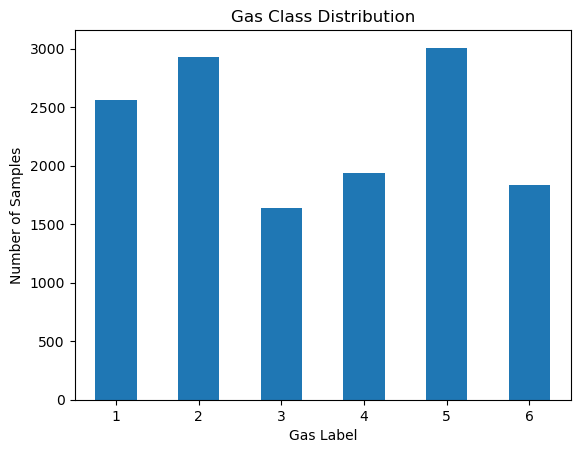

In [15]:
# Plot gas class distribution

gas_distribution.plot(kind="bar")

plt.xlabel("Gas Label")
plt.ylabel("Number of Samples")
plt.title("Gas Class Distribution")
plt.xticks(rotation=0)
plt.show()

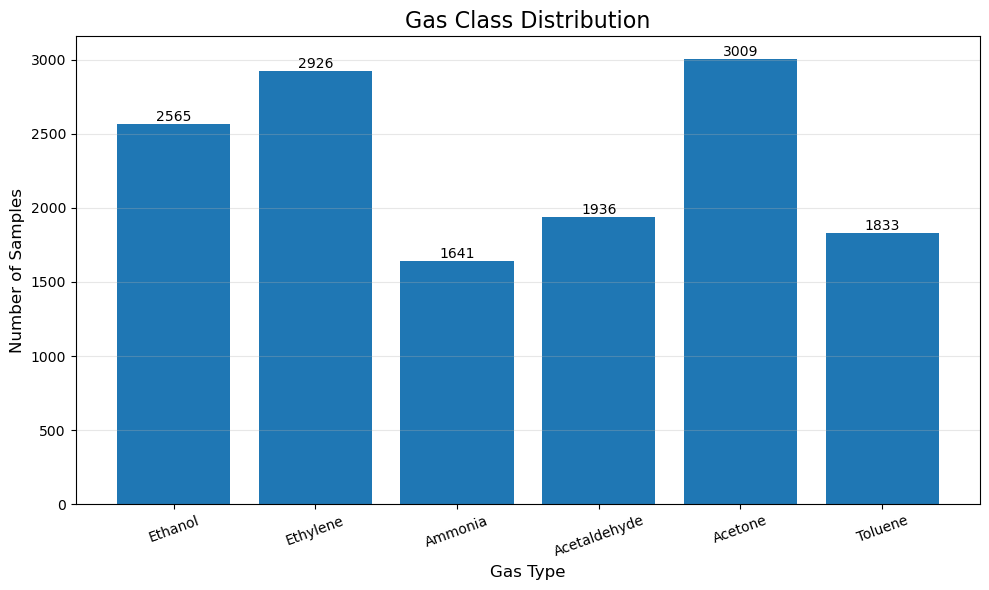

In [16]:
# Gas class distribution

gas_names = {
    1: "Ethanol",
    2: "Ethylene",
    3: "Ammonia",
    4: "Acetaldehyde",
    5: "Acetone",
    6: "Toluene"
}

gas_distribution = df["gas_label"].value_counts().sort_index()

plt.figure(figsize=(10, 6))

bars = plt.bar(
    [gas_names[i] for i in gas_distribution.index],
    gas_distribution.values
)

plt.title("Gas Class Distribution", fontsize=16)
plt.xlabel("Gas Type", fontsize=12)
plt.ylabel("Number of Samples", fontsize=12)

plt.xticks(rotation=20)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, gas_distribution.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

### Gas Class Proportion

The proportion of each gas class is analyzed to understand the contribution of each gas to the complete dataset.

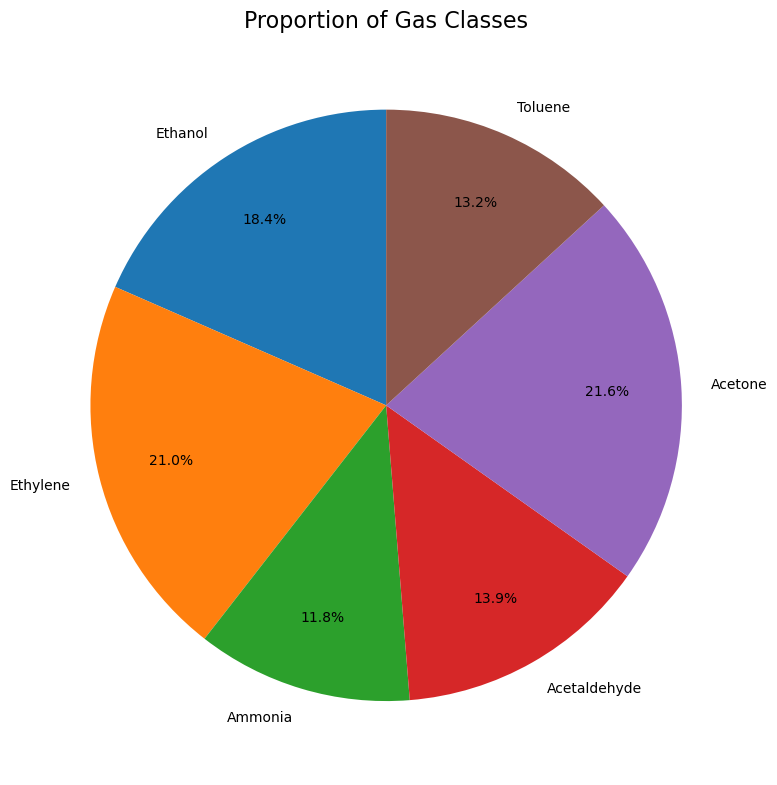

In [17]:
# Gas class proportion

gas_counts = df["gas_label"].value_counts().sort_index()

labels = [gas_names[i] for i in gas_counts.index]

plt.figure(figsize=(8, 8))

plt.pie(
    gas_counts.values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.75
)

plt.title("Proportion of Gas Classes", fontsize=16)
plt.tight_layout()
plt.show()

### Individual Sensor Distributions

The distributions of selected sensor features are visualized separately to clearly observe their individual ranges, spread, and frequency patterns.

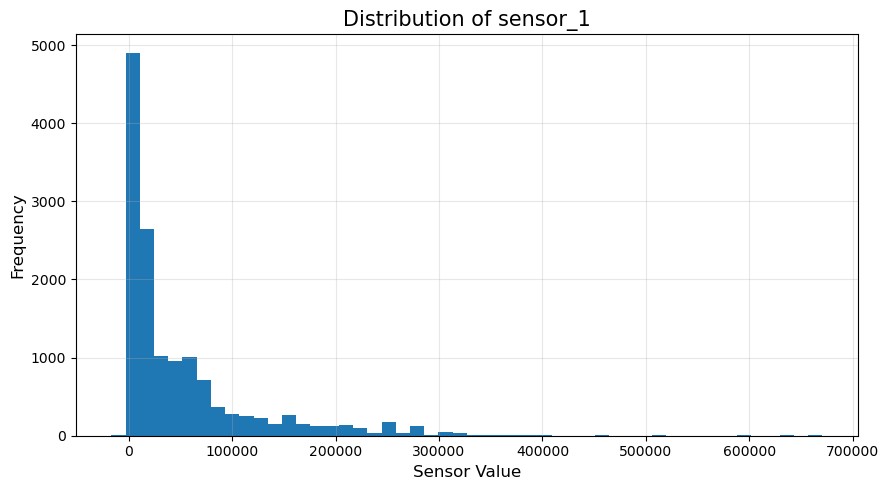

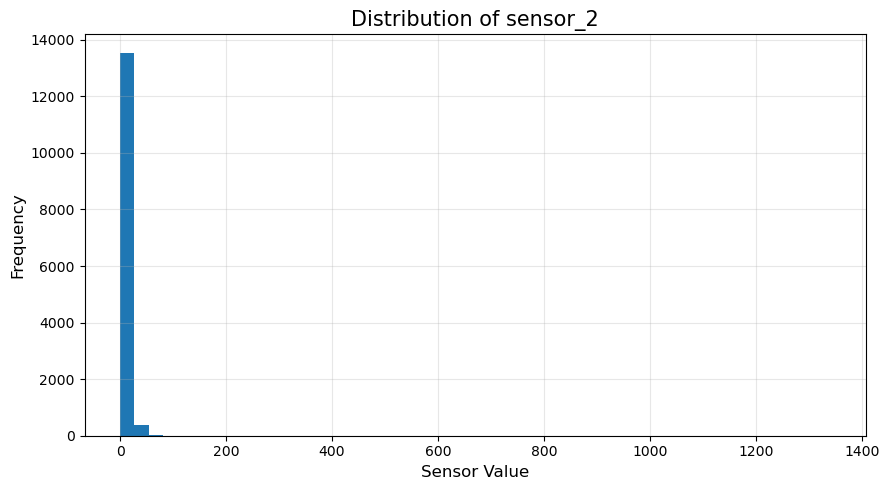

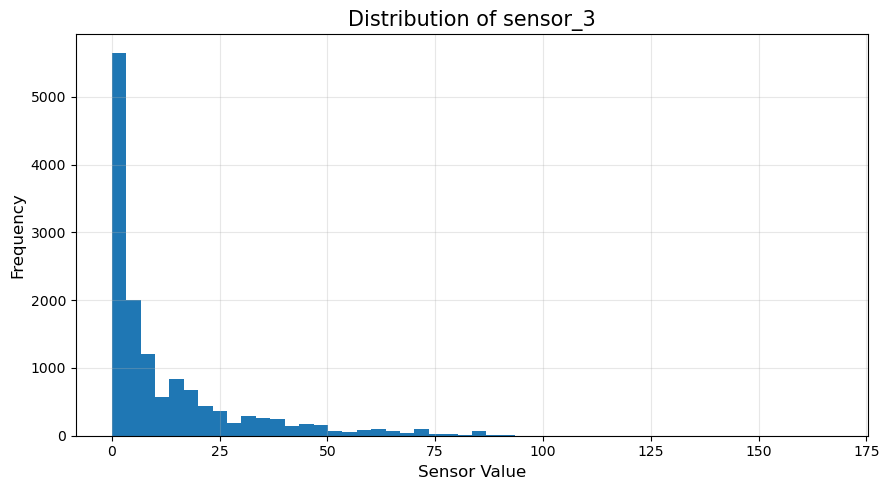

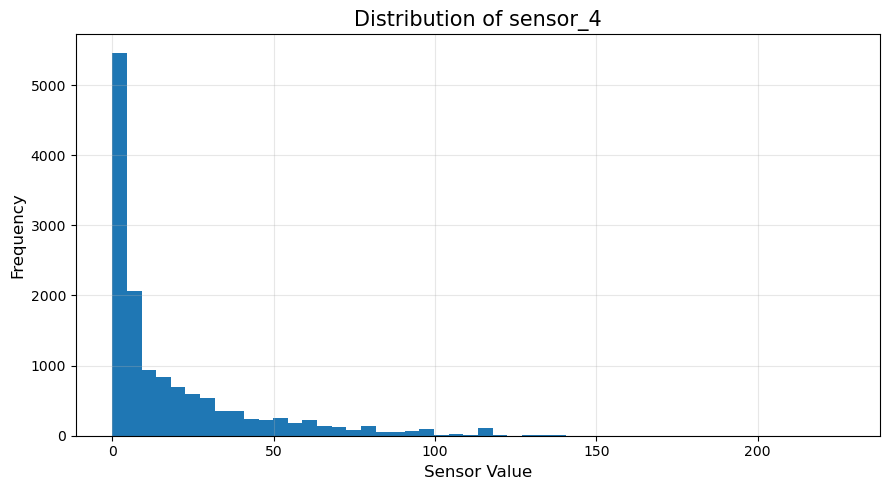

In [18]:
# Individual distributions of selected sensors

selected_sensors = ["sensor_1", "sensor_2", "sensor_3", "sensor_4"]

for sensor in selected_sensors:
    plt.figure(figsize=(9, 5))
    
    plt.hist(df[sensor], bins=50)
    
    plt.title(f"Distribution of {sensor}", fontsize=15)
    plt.xlabel("Sensor Value", fontsize=12)
    plt.ylabel("Frequency", fontsize=12)
    plt.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()

### Sensor Correlation Analysis

The correlation between the 128 sensor features is analyzed using a correlation heatmap.
This helps identify sensors that have similar or different measurement patterns.

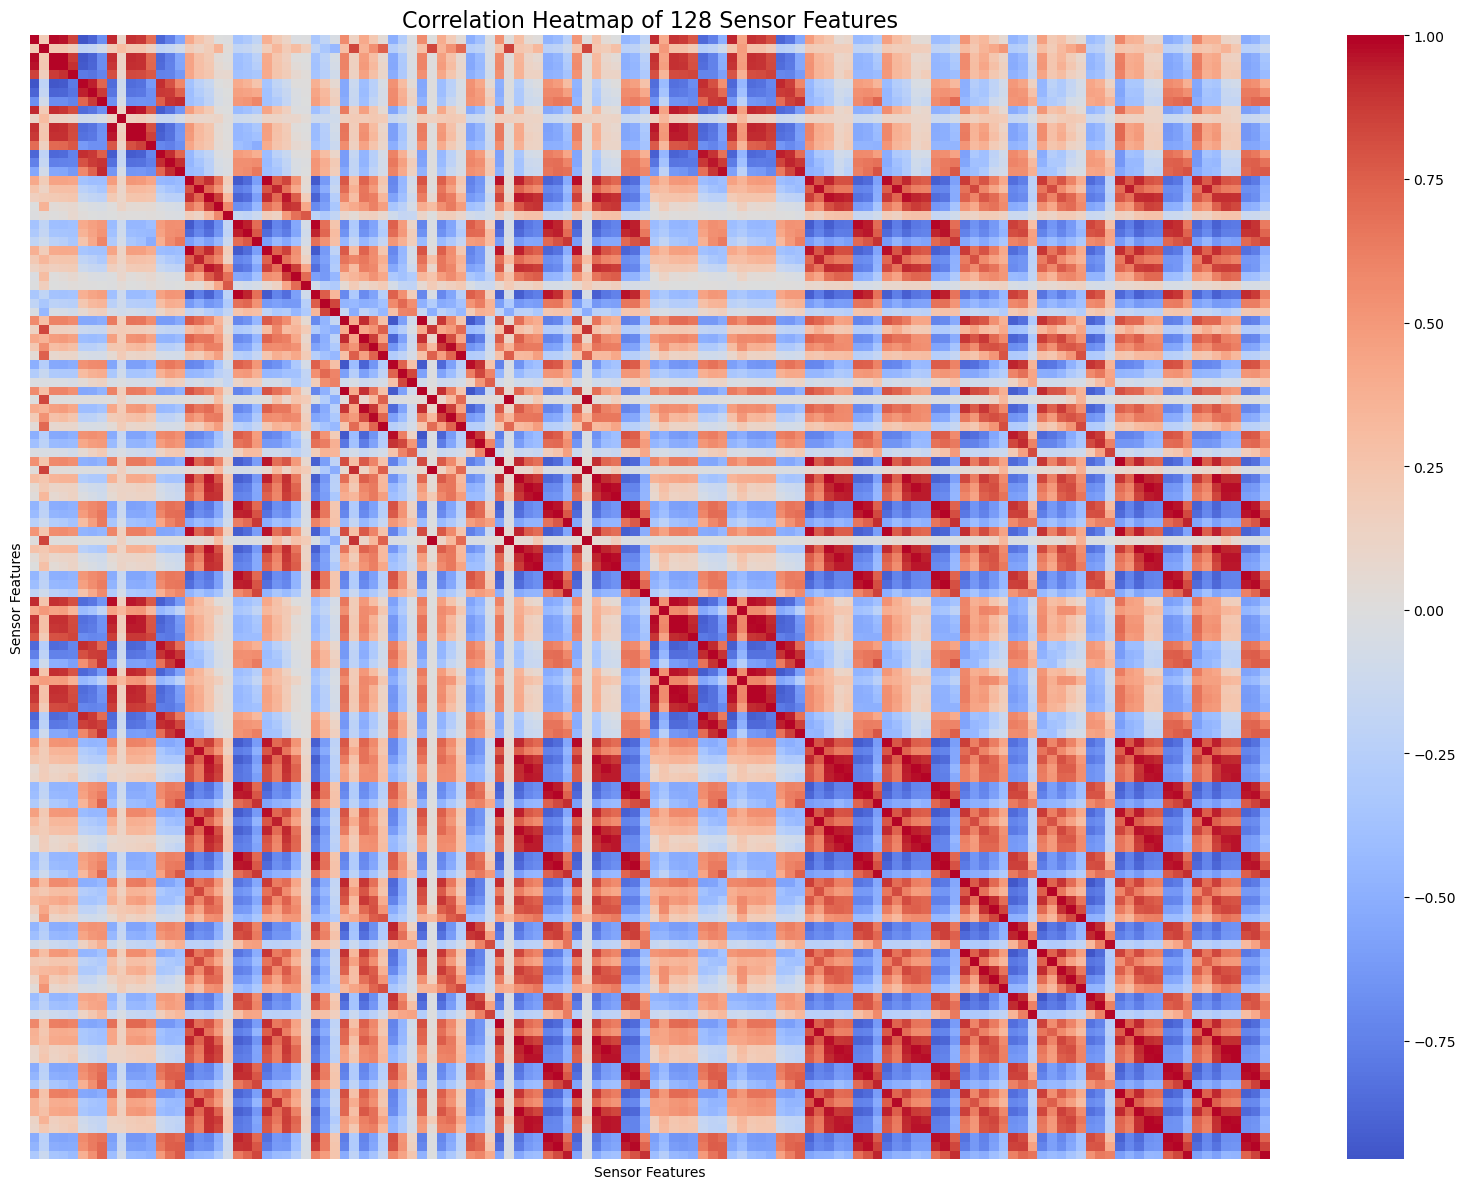

In [19]:
# Correlation heatmap of all 128 sensors

correlation_matrix = df[sensor_cols].corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=False
)

plt.title("Correlation Heatmap of 128 Sensor Features", fontsize=16)
plt.xlabel("Sensor Features")
plt.ylabel("Sensor Features")

plt.tight_layout()
plt.show()

## 5 Sensor Drift Analysis

Sensor drift is analyzed by comparing sensor measurements for the same gas across different batches.

Ethanol is selected as an example gas, and its sensor measurements from Batch 1 and Batch 10 are compared.
This helps identify changes in sensor response over different measurement batches.

In [20]:
# Select Ethanol samples from Batch 1 and Batch 10

ethanol_batch1 = df[
    (df["batch"] == 1) & (df["gas_label"] == 1)
]

ethanol_batch10 = df[
    (df["batch"] == 10) & (df["gas_label"] == 1)
]

print("Ethanol samples in Batch 1:", len(ethanol_batch1))
print("Ethanol samples in Batch 10:", len(ethanol_batch10))

Ethanol samples in Batch 1: 90
Ethanol samples in Batch 10: 600


### Ethanol Sensor Response Across Batches

The distribution of sensor_1 for Ethanol is compared between Batch 1 and Batch 10.
A change in the distribution can indicate a shift in sensor response across batches.

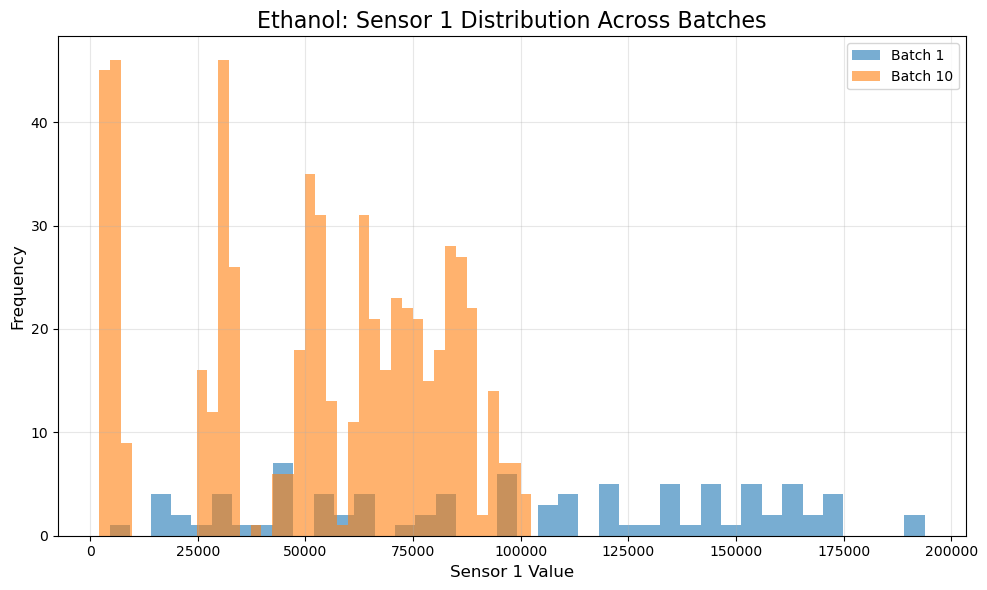

In [21]:
# Compare sensor_1 for Ethanol across Batch 1 and Batch 10

plt.figure(figsize=(10, 6))

plt.hist(
    ethanol_batch1["sensor_1"],
    bins=40,
    alpha=0.6,
    label="Batch 1"
)

plt.hist(
    ethanol_batch10["sensor_1"],
    bins=40,
    alpha=0.6,
    label="Batch 10"
)

plt.title("Ethanol: Sensor 1 Distribution Across Batches", fontsize=16)
plt.xlabel("Sensor 1 Value", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### PCA Visualization of Sensor Drift

Principal Component Analysis (PCA) is used to reduce the 128-dimensional sensor feature space to two principal components.

Ethanol samples from Batch 1 and Batch 10 are projected onto the first two principal components.

The visualization helps identify changes in the overall sensor response patterns between the two batches.

In [22]:
ethanol_drift = pd.concat(
    [ethanol_batch1, ethanol_batch10],
    ignore_index=True
)

X_ethanol = ethanol_drift[sensor_cols]
batch_labels = ethanol_drift["batch"]

### Standardization Before PCA

The sensor features are standardized so that sensors with larger numerical ranges do not dominate the PCA analysis.

In [23]:
from sklearn.preprocessing import StandardScaler

scaler_pca = StandardScaler()

X_ethanol_scaled = scaler_pca.fit_transform(X_ethanol)

### Applying Principal Component Analysis

PCA reduces the 128 sensor features to two principal components.

The explained variance shows how much information from the original sensor features is represented by PC1 and PC2.

In [24]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_ethanol_scaled)

print("Original number of features:", X_ethanol.shape[1])
print("Reduced number of features:", X_pca.shape[1])
print("Variance explained by PC1:", pca.explained_variance_ratio_[0])
print("Variance explained by PC2:", pca.explained_variance_ratio_[1])
print("Total variance explained:", pca.explained_variance_ratio_.sum())

Original number of features: 128
Reduced number of features: 2
Variance explained by PC1: 0.71863366227104
Variance explained by PC2: 0.13347419615040937
Total variance explained: 0.8521078584214493


### PCA Plot: Batch 1 vs Batch 10

The first two principal components are visualized to compare the sensor response patterns of Ethanol samples from Batch 1 and Batch 10.

A visible shift or separation between the batches may indicate changes in sensor response across batches.

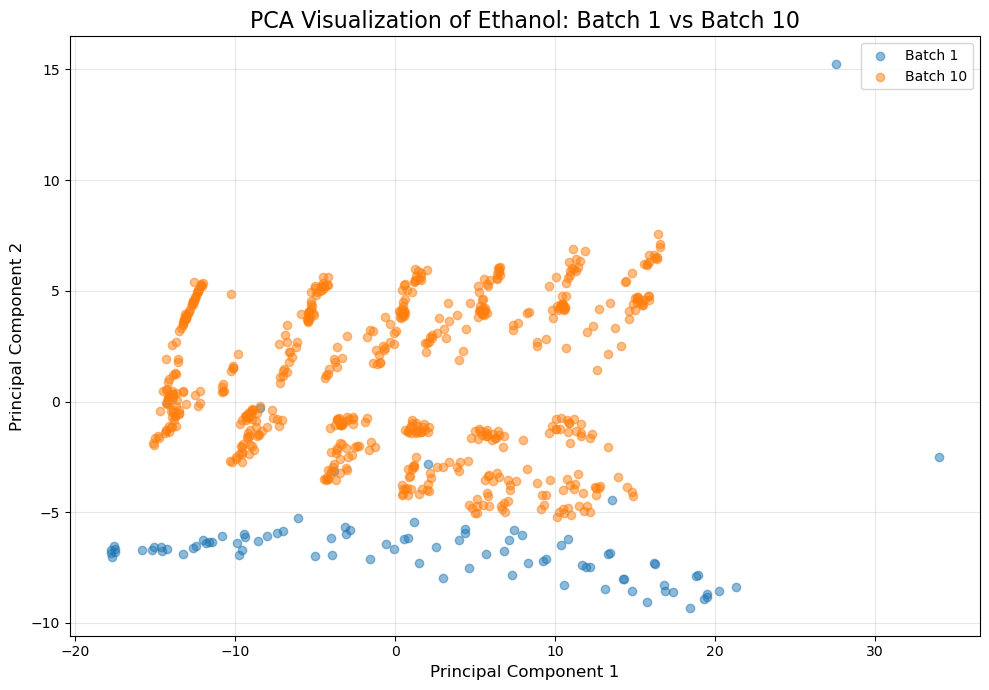

In [25]:
plt.figure(figsize=(10, 7))

for batch in [1, 10]:
    mask = batch_labels == batch
    
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        alpha=0.5,
        label=f"Batch {batch}"
    )

plt.title("PCA Visualization of Ethanol: Batch 1 vs Batch 10", fontsize=16)
plt.xlabel("Principal Component 1", fontsize=12)
plt.ylabel("Principal Component 2", fontsize=12)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Gas Classification

### Batch 1 Baseline Classification

Batch 1 is used as the baseline dataset for gas classification.

The 128 sensor features are used as input features, and the gas label is used as the target variable.

In [26]:
batch1_data = df[df["batch"] == 1].copy()

X_batch1 = batch1_data[sensor_cols]
y_batch1 = batch1_data["gas_label"]

print("Batch 1 samples:", len(batch1_data))
print("Number of sensor features:", X_batch1.shape[1])
print("X shape:", X_batch1.shape)
print("y shape:", y_batch1.shape)

Batch 1 samples: 445
Number of sensor features: 128
X shape: (445, 128)
y shape: (445,)


### Gas Classes in Batch 1

The distribution of gas classes in Batch 1 is checked before splitting the dataset.

This ensures that all gas classes are represented in the baseline classification dataset.

In [27]:
batch1_gas_counts = y_batch1.value_counts().sort_index()

for label, count in batch1_gas_counts.items():
    print(gas_names[label], ":", count)

Ethanol : 90
Ethylene : 98
Ammonia : 83
Acetaldehyde : 30
Acetone : 70
Toluene : 74


### Train-Test Split

Batch 1 data is divided into 80% training data and 20% testing data.

Stratified splitting is used so that the proportion of each gas class remains similar in both training and testing sets.

In [28]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_batch1,
    y_batch1,
    test_size=0.2,
    random_state=42,
    stratify=y_batch1
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 356
Testing samples: 89


### Feature Scaling

StandardScaler is used to standardize the sensor features.

The scaler is fitted only on the training data and then applied to both training and testing data to avoid data leakage.

In [29]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (356, 128)
Scaled testing shape: (89, 128)


### Random Forest Classification

Random Forest is trained on the Batch 1 training data.

The trained model is then used to predict the gas classes of the unseen Batch 1 test data.

In [30]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

rf_pred = rf_model.predict(X_test_scaled)

print("Random Forest training completed.")

Random Forest training completed.


### Random Forest Performance

The Random Forest model is evaluated using accuracy and a classification report.

The classification report provides precision, recall, and F1-score for each gas class.

In [31]:
from sklearn.metrics import accuracy_score, classification_report

rf_accuracy = accuracy_score(y_test, rf_pred)

print("Random Forest Accuracy:", rf_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_pred,
        labels=sorted(gas_names.keys()),
        target_names=[gas_names[i] for i in sorted(gas_names.keys())],
        zero_division=0
    )
)

Random Forest Accuracy: 0.9662921348314607

Classification Report:
              precision    recall  f1-score   support

     Ethanol       1.00      1.00      1.00        18
    Ethylene       0.95      1.00      0.98        20
     Ammonia       1.00      0.94      0.97        16
Acetaldehyde       1.00      0.67      0.80         6
     Acetone       1.00      1.00      1.00        14
     Toluene       0.88      1.00      0.94        15

    accuracy                           0.97        89
   macro avg       0.97      0.93      0.95        89
weighted avg       0.97      0.97      0.96        89



### Random Forest Confusion Matrix

The confusion matrix shows the number of correctly and incorrectly classified samples for each gas class.

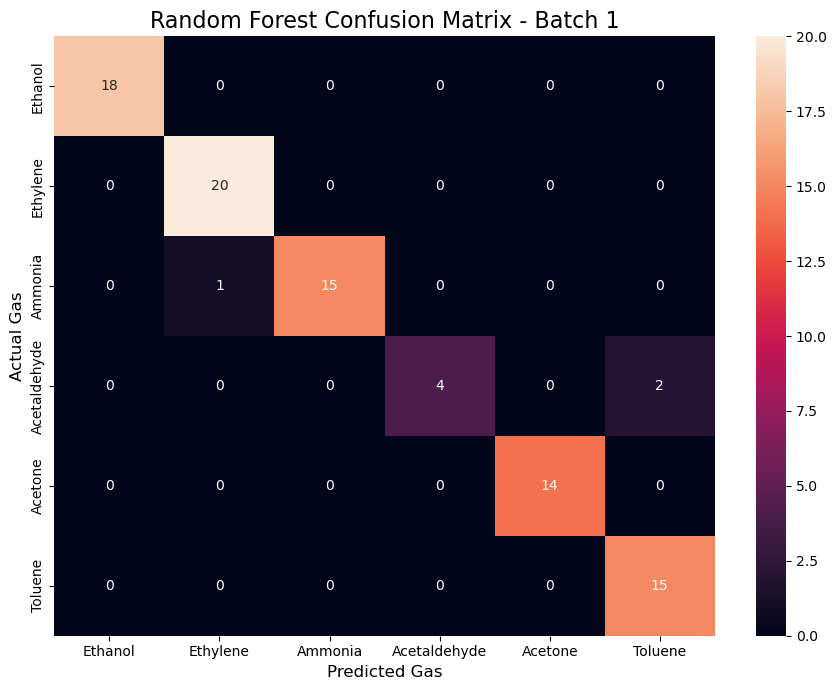

In [32]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

rf_cm = confusion_matrix(
    y_test,
    rf_pred,
    labels=sorted(gas_names.keys())
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    rf_cm,
    annot=True,
    fmt="d",
    xticklabels=[gas_names[i] for i in sorted(gas_names.keys())],
    yticklabels=[gas_names[i] for i in sorted(gas_names.keys())]
)

plt.title("Random Forest Confusion Matrix - Batch 1", fontsize=16)
plt.xlabel("Predicted Gas", fontsize=12)
plt.ylabel("Actual Gas", fontsize=12)
plt.tight_layout()
plt.show()

### Support Vector Machine Classification

A Support Vector Machine (SVM) with an RBF kernel is trained using the standardized sensor features.

The model is evaluated on the unseen Batch 1 test data.

In [33]:
from sklearn.svm import SVC

svm_model = SVC(
    kernel="rbf",
    C=10,
    gamma="scale"
)

svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

print("SVM training completed.")

SVM training completed.


### SVM Performance

The SVM model is evaluated using accuracy and a classification report.

In [34]:
svm_accuracy = accuracy_score(y_test, svm_pred)

print("SVM Accuracy:", svm_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        svm_pred,
        labels=sorted(gas_names.keys()),
        target_names=[gas_names[i] for i in sorted(gas_names.keys())],
        zero_division=0
    )
)

SVM Accuracy: 0.9775280898876404

Classification Report:
              precision    recall  f1-score   support

     Ethanol       1.00      1.00      1.00        18
    Ethylene       0.95      1.00      0.98        20
     Ammonia       1.00      0.94      0.97        16
Acetaldehyde       1.00      0.83      0.91         6
     Acetone       1.00      1.00      1.00        14
     Toluene       0.94      1.00      0.97        15

    accuracy                           0.98        89
   macro avg       0.98      0.96      0.97        89
weighted avg       0.98      0.98      0.98        89



### SVM Confusion Matrix

The confusion matrix shows the actual and predicted gas classes for the SVM classifier.

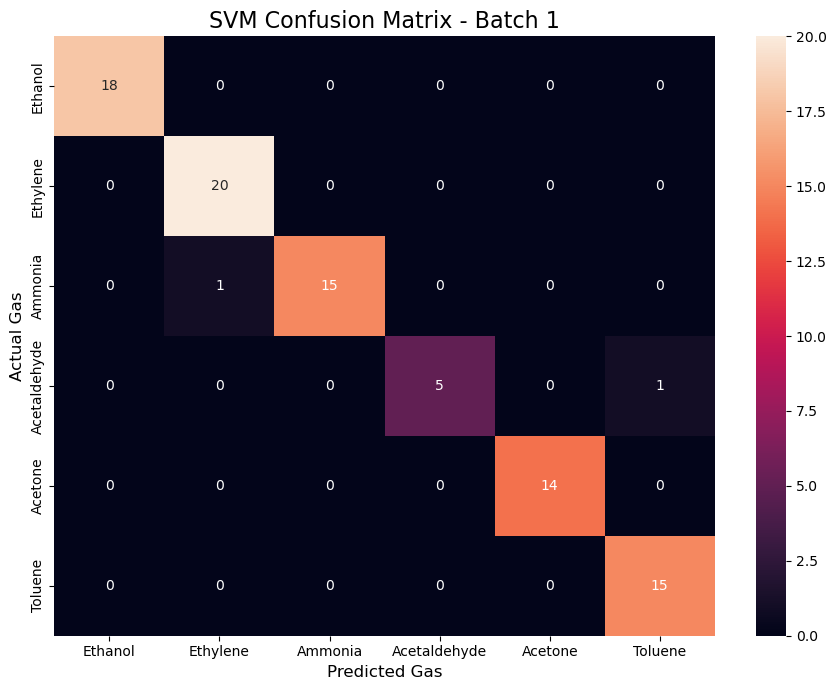

In [35]:
svm_cm = confusion_matrix(
    y_test,
    svm_pred,
    labels=sorted(gas_names.keys())
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    svm_cm,
    annot=True,
    fmt="d",
    xticklabels=[gas_names[i] for i in sorted(gas_names.keys())],
    yticklabels=[gas_names[i] for i in sorted(gas_names.keys())]
)

plt.title("SVM Confusion Matrix - Batch 1", fontsize=16)
plt.xlabel("Predicted Gas", fontsize=12)
plt.ylabel("Actual Gas", fontsize=12)

plt.tight_layout()
plt.show()

### XGBoost Classification

XGBoost is used as the third baseline classification model.

The gas labels are encoded from 1–6 to 0–5 for XGBoost multiclass classification and converted back to the original gas labels after prediction.

In [36]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_xgb = label_encoder.fit_transform(y_train)
y_test_xgb = label_encoder.transform(y_test)

print("Original labels:", sorted(y_train.unique()))
print("Encoded labels:", sorted(y_train_xgb))

Original labels: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]
Encoded labels: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.

### Training the XGBoost Model

The XGBoost classifier is trained using the standardized Batch 1 sensor features.

In [37]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=6,
    eval_metric="mlogloss",
    random_state=42
)

xgb_model.fit(X_train_scaled, y_train_xgb)

xgb_pred_encoded = xgb_model.predict(X_test_scaled).astype(int)

xgb_pred = label_encoder.inverse_transform(xgb_pred_encoded)

print("XGBoost training completed.")

XGBoost training completed.


### XGBoost Performance

The XGBoost model is evaluated using accuracy and a classification report.

In [38]:
xgb_accuracy = accuracy_score(y_test, xgb_pred)

print("XGBoost Accuracy:", xgb_accuracy)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        xgb_pred,
        labels=sorted(gas_names.keys()),
        target_names=[gas_names[i] for i in sorted(gas_names.keys())],
        zero_division=0
    )
)

XGBoost Accuracy: 0.9438202247191011

Classification Report:
              precision    recall  f1-score   support

     Ethanol       0.95      1.00      0.97        18
    Ethylene       0.95      1.00      0.98        20
     Ammonia       1.00      0.94      0.97        16
Acetaldehyde       0.67      0.67      0.67         6
     Acetone       1.00      0.86      0.92        14
     Toluene       0.94      1.00      0.97        15

    accuracy                           0.94        89
   macro avg       0.92      0.91      0.91        89
weighted avg       0.95      0.94      0.94        89



### XGBoost Confusion Matrix

The confusion matrix shows the actual and predicted gas classes for the XGBoost classifier.

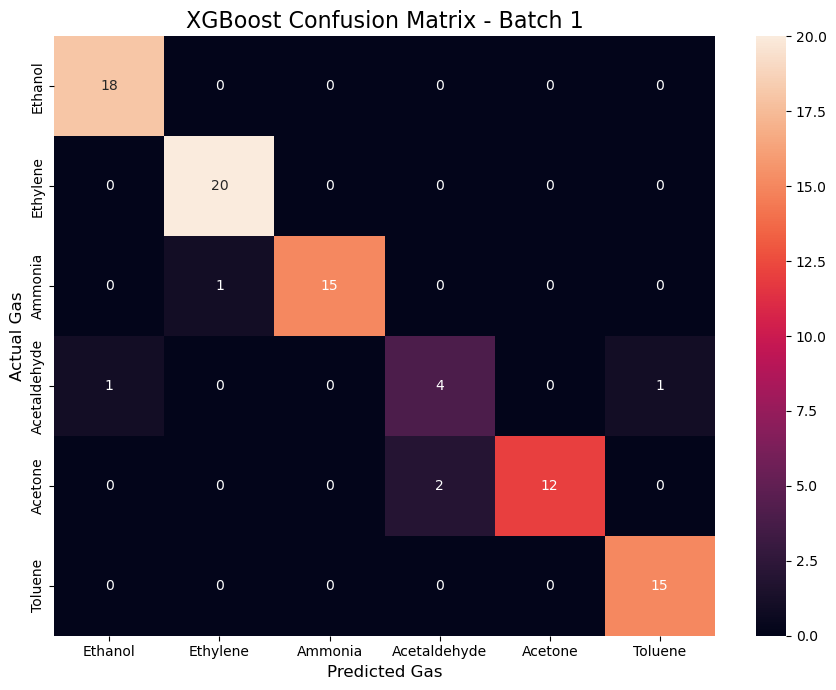

In [39]:
xgb_cm = confusion_matrix(
    y_test,
    xgb_pred,
    labels=sorted(gas_names.keys())
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    xgb_cm,
    annot=True,
    fmt="d",
    xticklabels=[gas_names[i] for i in sorted(gas_names.keys())],
    yticklabels=[gas_names[i] for i in sorted(gas_names.keys())]
)

plt.title("XGBoost Confusion Matrix - Batch 1", fontsize=16)
plt.xlabel("Predicted Gas", fontsize=12)
plt.ylabel("Actual Gas", fontsize=12)

plt.tight_layout()
plt.show()

### Baseline Model Comparison

The performance of Random Forest, SVM, and XGBoost is compared using classification accuracy on the unseen Batch 1 test set.

This establishes the baseline performance before evaluating the models across different batches.

In [40]:
model_results = pd.DataFrame({
    "Model": ["Random Forest", "SVM", "XGBoost"],
    "Accuracy": [rf_accuracy, svm_accuracy, xgb_accuracy]
})

print(model_results)

           Model  Accuracy
0  Random Forest  0.966292
1            SVM  0.977528
2        XGBoost  0.943820


### Baseline Accuracy Comparison

The accuracy of the three classification models is visualized to provide a clear comparison of their baseline performance on Batch 1.

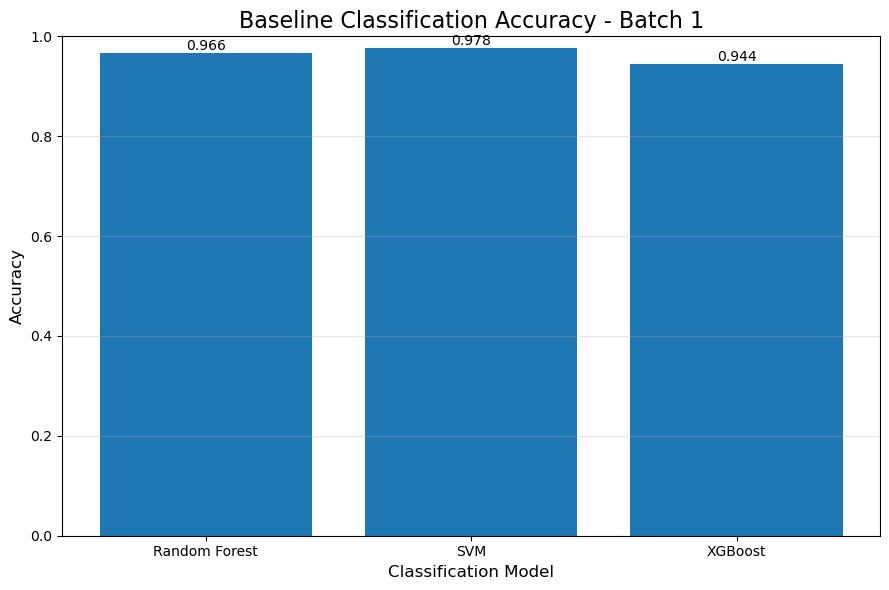

In [41]:
plt.figure(figsize=(9, 6))

bars = plt.bar(
    model_results["Model"],
    model_results["Accuracy"]
)

plt.title("Baseline Classification Accuracy - Batch 1", fontsize=16)
plt.xlabel("Classification Model", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, model_results["Accuracy"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

## Cross-Batch Testing

The trained models are evaluated on different batches without retraining.
This helps analyze the effect of sensor drift on classification performance.

In [42]:
batch_results = []

for batch_number in range(2, 11):

    batch_data = df[df["batch"] == batch_number]

    X_batch = batch_data[sensor_cols]
    y_batch = batch_data["gas_label"]

    X_batch_scaled = scaler.transform(X_batch)

    rf_pred_batch = rf_model.predict(X_batch_scaled)
    svm_pred_batch = svm_model.predict(X_batch_scaled)

    xgb_pred_encoded_batch = xgb_model.predict(X_batch_scaled).astype(int)
    xgb_pred_batch = label_encoder.inverse_transform(xgb_pred_encoded_batch)

    rf_acc = accuracy_score(y_batch, rf_pred_batch)
    svm_acc = accuracy_score(y_batch, svm_pred_batch)
    xgb_acc = accuracy_score(y_batch, xgb_pred_batch)

    batch_results.append([
        batch_number,
        rf_acc,
        svm_acc,
        xgb_acc
    ])

cross_batch_results = pd.DataFrame(
    batch_results,
    columns=["Batch", "Random Forest", "SVM", "XGBoost"]
)

cross_batch_results

,Batch,Random Forest,SVM,XGBoost
0,2,0.693730,0.673633,0.792605
1,3,0.725725,0.536570,0.766709
2,4,0.521739,0.397516,0.645963
3,5,0.436548,0.238579,0.406091
4,6,0.486087,0.433913,0.461739
5,7,0.399668,0.366454,0.363410
6,8,0.210884,0.193878,0.183673
7,9,0.395745,0.344681,0.197872
8,10,0.324722,0.442500,0.308889


## Cross-Batch Accuracy Comparison

The classification accuracy of the three models is compared across different batches.
A decrease in accuracy across batches may indicate the effect of sensor drift.

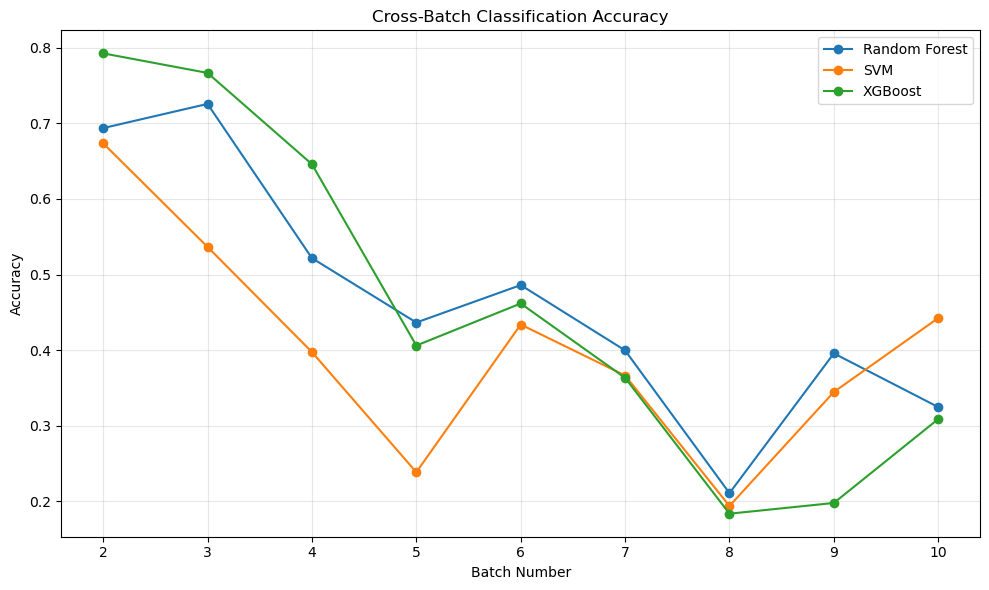

In [43]:
plt.figure(figsize=(10, 6))

plt.plot(
    cross_batch_results["Batch"],
    cross_batch_results["Random Forest"],
    marker="o",
    label="Random Forest"
)

plt.plot(
    cross_batch_results["Batch"],
    cross_batch_results["SVM"],
    marker="o",
    label="SVM"
)

plt.plot(
    cross_batch_results["Batch"],
    cross_batch_results["XGBoost"],
    marker="o",
    label="XGBoost"
)

plt.xlabel("Batch Number")
plt.ylabel("Accuracy")
plt.title("Cross-Batch Classification Accuracy")
plt.xticks(range(2, 11))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Performance Degradation Analysis

The change in classification accuracy from the Batch 1 baseline to later batches is calculated.
This provides a quantitative measure of performance degradation caused by changing sensor conditions.

In [44]:
baseline_results = pd.DataFrame({
    "Model": ["Random Forest", "SVM", "XGBoost"],
    "Batch 1 Accuracy": [
        rf_accuracy,
        svm_accuracy,
        accuracy_score(y_test, xgb_pred)
    ]
})

baseline_results

,Model,Batch 1 Accuracy
0,Random Forest,0.966292
1,SVM,0.977528
2,XGBoost,0.943820


### Accuracy Change Across Batches

The accuracy change is calculated by comparing the accuracy of each later batch with the corresponding Batch 1 baseline accuracy.

In [45]:
for model in ["Random Forest", "SVM", "XGBoost"]:

    baseline_accuracy = baseline_results.loc[
        baseline_results["Model"] == model,
        "Batch 1 Accuracy"
    ].values[0]

    cross_batch_results[model + " Change"] = (
        cross_batch_results[model] - baseline_accuracy
    )

cross_batch_results

,Batch,Random Forest,SVM,XGBoost,Random Forest Change,SVM Change,XGBoost Change
0,2,0.693730,0.673633,0.792605,-0.272562,-0.303895,-0.151216
1,3,0.725725,0.536570,0.766709,-0.240567,-0.440958,-0.177112
2,4,0.521739,0.397516,0.645963,-0.444553,-0.580013,-0.297857
3,5,0.436548,0.238579,0.406091,-0.529744,-0.738949,-0.537729
4,6,0.486087,0.433913,0.461739,-0.480205,-0.543615,-0.482081
5,7,0.399668,0.366454,0.363410,-0.566624,-0.611074,-0.580410
6,8,0.210884,0.193878,0.183673,-0.755408,-0.783651,-0.760147
7,9,0.395745,0.344681,0.197872,-0.570547,-0.632847,-0.745948
8,10,0.324722,0.442500,0.308889,-0.641570,-0.535028,-0.634931


## Model Selection

The models are compared based on baseline accuracy and cross-batch performance.

### Cross-Batch Performance

In [46]:
cross_batch_results

,Batch,Random Forest,SVM,XGBoost,Random Forest Change,SVM Change,XGBoost Change
0,2,0.693730,0.673633,0.792605,-0.272562,-0.303895,-0.151216
1,3,0.725725,0.536570,0.766709,-0.240567,-0.440958,-0.177112
2,4,0.521739,0.397516,0.645963,-0.444553,-0.580013,-0.297857
3,5,0.436548,0.238579,0.406091,-0.529744,-0.738949,-0.537729
4,6,0.486087,0.433913,0.461739,-0.480205,-0.543615,-0.482081
5,7,0.399668,0.366454,0.363410,-0.566624,-0.611074,-0.580410
6,8,0.210884,0.193878,0.183673,-0.755408,-0.783651,-0.760147
7,9,0.395745,0.344681,0.197872,-0.570547,-0.632847,-0.745948
8,10,0.324722,0.442500,0.308889,-0.641570,-0.535028,-0.634931


### Average Cross-Batch Accuracy

In [47]:
average_cross_batch_accuracy = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVM",
        "XGBoost"
    ],
    "Average Cross-Batch Accuracy": [
        cross_batch_results["Random Forest"].mean(),
        cross_batch_results["SVM"].mean(),
        cross_batch_results["XGBoost"].mean()
    ]
})

average_cross_batch_accuracy

,Model,Average Cross-Batch Accuracy
0,Random Forest,0.466094
1,SVM,0.403080
2,XGBoost,0.458550


### Average Accuracy Change

In [48]:
average_accuracy_change = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVM",
        "XGBoost"
    ],
    "Average Accuracy Change": [
        cross_batch_results["Random Forest Change"].mean(),
        cross_batch_results["SVM Change"].mean(),
        cross_batch_results["XGBoost Change"].mean()
    ]
})

average_accuracy_change

,Model,Average Accuracy Change
0,Random Forest,-0.500198
1,SVM,-0.574448
2,XGBoost,-0.485270


### Final Model Comparison

In [49]:
model_selection = pd.DataFrame({
    "Model": [
        "Random Forest",
        "SVM",
        "XGBoost"
    ],
    "Baseline Accuracy": [
        rf_accuracy,
        svm_accuracy,
        xgb_accuracy
    ],
    "Average Cross-Batch Accuracy": [
        cross_batch_results["Random Forest"].mean(),
        cross_batch_results["SVM"].mean(),
        cross_batch_results["XGBoost"].mean()
    ],
    "Average Accuracy Change": [
        cross_batch_results["Random Forest Change"].mean(),
        cross_batch_results["SVM Change"].mean(),
        cross_batch_results["XGBoost Change"].mean()
    ]
})

model_selection

,Model,Baseline Accuracy,Average Cross-Batch Accuracy,Average Accuracy Change
0,Random Forest,0.966292,0.466094,-0.500198
1,SVM,0.977528,0.403080,-0.574448
2,XGBoost,0.943820,0.458550,-0.485270


### Selected Classification Model"

In [50]:
selected_model = model_selection.loc[
    model_selection["Average Cross-Batch Accuracy"].idxmax(),
    "Model"
]

print("Selected Model:", selected_model)

Selected Model: Random Forest


### Model Selection Result

The model with the highest average cross-batch accuracy is selected for the subsequent drift adaptation experiment.

---
# PART 2: Sensor Drift Detection, Drift Compensation and Final Pipeline

The first part of this notebook trained three classifiers on **Batch 1** and showed that their accuracy collapses on later batches. This part completes the project:

| Step | What is done |
|---|---|
| 1 | Finalise the classification model |
| 2 | Batch-wise train/test setup, cross-batch testing, baseline accuracy, performance degradation |
| 3 | Sensor drift detection: batch-wise mean/variance, distribution shift, drift score, visualisation, PCA |
| 4 | Drift compensation: batch-wise standardisation and reference-batch correction |
| 5 | Re-test the selected model on compensated data and compare before vs after |
| 6 | Statistical validation (mean ± std, paired tests, multi-seed, bootstrap) |
| 7 | Final pipeline **Input → Preprocessing → Drift Compensation → Selected Model → Gas Class**, results table, saved outputs |
| 8 | Flask integration |

> Part 2 only needs the dataframe `df` created in Part 1 (columns `batch`, `gas_label`, `sensor_1 ... sensor_128`). Run Part 1 first, then run this part from top to bottom.

## 7. Setup, Helper Functions and Output Folders

The core code (classifier wrapper, drift compensator, drift metrics, statistical tests, final pipeline class) is defined once in the next cells so that the Flask app can use exactly the same logic.

In [51]:
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix)
from xgboost import XGBClassifier

### 7.1 Constants

In [52]:
SENSOR_COLS = [f"sensor_{i}" for i in range(1, 129)]
GAS_NAMES = {1: "Ethanol", 2: "Ethylene", 3: "Ammonia",
             4: "Acetaldehyde", 5: "Acetone", 6: "Toluene"}
GAS_LABELS = sorted(GAS_NAMES)
MODEL_NAMES = ["Random Forest", "SVM", "XGBoost"]
BATCHES = list(range(1, 11))
REF_BATCH = 1
CORAL_LAMBDA = 0.5
RANDOM_STATE = 42

COMPENSATION_METHODS = {
    "none": "No compensation (baseline)",
    "batch_standardization": "Batch-wise Standardization",
    "reference_mean": "Reference Mean Alignment",
    "reference_coral": "Reference CORAL Alignment",
}

### 7.2 Classifier wrapper (handles label encoding for every model type)

In [53]:
class GasClassifier:
    """Random Forest / SVM / XGBoost behind one fit-predict interface."""

    def __init__(self, name, seed=RANDOM_STATE, probability=False):
        self.name, self.seed, self.probability = name, seed, probability
        if name == "Random Forest":
            self.model = RandomForestClassifier(
                n_estimators=300, random_state=seed, n_jobs=-1)
        elif name == "SVM":
            self.model = SVC(kernel="rbf", C=10, gamma="scale",
                             probability=probability, random_state=seed)
        elif name == "XGBoost":
            self.model = XGBClassifier(
                n_estimators=300, max_depth=6, learning_rate=0.05,
                subsample=0.8, colsample_bytree=0.8,
                objective="multi:softprob", eval_metric="mlogloss",
                random_state=seed)
        else:
            raise ValueError(f"Unknown model: {name}")

    def fit(self, X, y):
        self.le = LabelEncoder().fit(y)
        self.model.fit(X, self.le.transform(y))
        return self

    def predict(self, X):
        pred = np.asarray(self.model.predict(X)).astype(int)
        return self.le.inverse_transform(pred)

    def predict_proba(self, X):
        if hasattr(self.model, "predict_proba") and (self.name != "SVM" or self.probability):
            return self.model.predict_proba(X)
        return None

### 7.3 Drift compensation

In [54]:
def _sym_power(M, power):
    vals, vecs = np.linalg.eigh(M)
    vals = np.clip(vals, 1e-8, None) ** power
    return (vecs * vals) @ vecs.T


class BatchCompensator:
    """Maps every batch towards the reference batch (Batch 1).

    method = none                  -> identity
             batch_standardization -> z-score using the batch's own mean/std
             reference_mean        -> x - mean_batch + mean_ref
             reference_coral       -> mean + covariance (CORAL) alignment to ref

    Only UNLABELLED samples of each batch are used to estimate statistics.
    """

    def __init__(self, method="none", ref_batch=REF_BATCH, coral_lambda=CORAL_LAMBDA):
        if method not in COMPENSATION_METHODS:
            raise ValueError(f"Unknown method: {method}")
        self.method, self.ref_batch, self.coral_lambda = method, ref_batch, coral_lambda

    def fit(self, X, batch):
        X, batch = np.asarray(X, float), np.asarray(batch)
        self.mu, self.sd, self.T = {}, {}, {}
        for b in np.unique(batch):
            Xb = X[batch == b]
            sd = Xb.std(axis=0, ddof=1)
            self.mu[int(b)] = Xb.mean(axis=0)
            self.sd[int(b)] = np.where(sd < 1e-12, 1.0, sd)
        self.mu_ref, self.sd_ref = self.mu[self.ref_batch], self.sd[self.ref_batch]
        if self.method == "reference_coral":
            lam = self.coral_lambda
            eye = np.eye(X.shape[1])
            Xr = (X[batch == self.ref_batch] - self.mu_ref) / self.sd_ref
            Cr_half = _sym_power(np.cov(Xr, rowvar=False) + lam * eye, 0.5)
            for b in self.mu:
                Xb = (X[batch == b] - self.mu[b]) / self.sd_ref
                Cb_inv_half = _sym_power(np.cov(Xb, rowvar=False) + lam * eye, -0.5)
                self.T[b] = Cb_inv_half @ Cr_half
        return self

    def transform(self, X, batch):
        X = np.atleast_2d(np.asarray(X, float))
        b = int(batch)
        if self.method == "none":
            return X.copy()
        if b not in self.mu:
            raise KeyError(f"No statistics available for batch {b}")
        if self.method == "batch_standardization":
            return (X - self.mu[b]) / self.sd[b]
        if self.method == "reference_mean":
            return X - self.mu[b] + self.mu_ref
        # reference_coral
        Z = ((X - self.mu[b]) / self.sd_ref) @ self.T[b]
        return Z * self.sd_ref + self.mu_ref


def compensate_all(X, batch, comp):
    """Apply a fitted compensator batch by batch."""
    X, batch = np.asarray(X, float), np.asarray(batch)
    out = np.empty_like(X)
    for b in np.unique(batch):
        m = batch == b
        out[m] = comp.transform(X[m], b)
    return out

### 7.4 Experiment 1: train on Batch 1 (80 %), test on Batch 1 hold-out (20 %) and on every later batch (cross-batch testing)

In [55]:
def run_setup_a(X, y, batch, method="none", model_names=MODEL_NAMES,
                seed=RANDOM_STATE, probability=False):
    X, y, batch = np.asarray(X, float), np.asarray(y), np.asarray(batch)
    comp = BatchCompensator(method).fit(X, batch)
    Xt = compensate_all(X, batch, comp)

    ref_idx = np.where(batch == REF_BATCH)[0]
    train_idx, test_idx = train_test_split(
        ref_idx, test_size=0.2, random_state=seed, stratify=y[ref_idx])

    scaler = StandardScaler().fit(Xt[train_idx])
    Xtr = scaler.transform(Xt[train_idx])

    preds, models = {}, {}
    for name in model_names:
        model = GasClassifier(name, seed, probability).fit(Xtr, y[train_idx])
        p = {1: (y[test_idx], model.predict(scaler.transform(Xt[test_idx])))}
        for k in BATCHES[1:]:
            idx = np.where(batch == k)[0]
            p[k] = (y[idx], model.predict(scaler.transform(Xt[idx])))
        preds[name], models[name] = p, model
    return dict(preds=preds, models=models, comp=comp, scaler=scaler,
                Xt=Xt, train_idx=train_idx, test_idx=test_idx)


def batch_metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0)
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=p, recall=r, f1=f)


def metrics_table(preds_one_model):
    """preds_one_model: {batch: (y_true, y_pred)} -> DataFrame (Batch 1..10)."""
    rows = [dict(Batch=k, **batch_metrics(*preds_one_model[k])) for k in BATCHES]
    return pd.DataFrame(rows)


def pooled(preds_one_model, batches=BATCHES[1:]):
    yt = np.concatenate([preds_one_model[k][0] for k in batches])
    yp = np.concatenate([preds_one_model[k][1] for k in batches])
    return yt, yp

### 7.5 Drift detection

In [56]:
def ks_stat(a, b):
    """Two-sample Kolmogorov-Smirnov statistic (0 = identical, 1 = disjoint)."""
    a, b = np.sort(a), np.sort(b)
    allv = np.concatenate([a, b])
    cdf_a = np.searchsorted(a, allv, side="right") / len(a)
    cdf_b = np.searchsorted(b, allv, side="right") / len(b)
    return float(np.max(np.abs(cdf_a - cdf_b)))


def mean_ks(A, B):
    return float(np.mean([ks_stat(A[:, j], B[:, j]) for j in range(A.shape[1])]))


def drift_table(X, y, batch, ref=REF_BATCH, min_class_samples=5):
    """Drift of every batch relative to the reference batch.

    mean_shift : mean_j |mu_bj - mu_refj| / sd_refj
    var_shift  : mean_j |log(var_bj / var_refj)|
    ks_pooled  : mean KS statistic over sensors (all gases pooled)
    drift_score: mean KS statistic over sensors AND gases, computed per gas so
                 that changes in gas mixture between batches are not mistaken
                 for sensor drift  (0 = no drift, 1 = complete drift)
    """
    X, y, batch = np.asarray(X, float), np.asarray(y), np.asarray(batch)
    Xr, yr = X[batch == ref], y[batch == ref]
    mu_r, sd_r, var_r = Xr.mean(0), Xr.std(0, ddof=1) + 1e-12, Xr.var(0, ddof=1) + 1e-12
    rows = []
    for b in BATCHES:
        Xb, yb = X[batch == b], y[batch == b]
        per_gas = []
        for g in GAS_LABELS:
            A, B = Xr[yr == g], Xb[yb == g]
            if len(A) >= min_class_samples and len(B) >= min_class_samples:
                per_gas.append(mean_ks(A, B))
        rows.append(dict(
            Batch=b,
            mean_shift=float(np.mean(np.abs(Xb.mean(0) - mu_r) / sd_r)),
            var_shift=float(np.mean(np.abs(np.log((Xb.var(0, ddof=1) + 1e-12) / var_r)))),
            ks_pooled=mean_ks(Xr, Xb),
            drift_score=float(np.mean(per_gas)) if per_gas else np.nan))
    return pd.DataFrame(rows)

### 7.6 Statistical validation helpers

In [57]:
def paired_stats(before, after):
    before, after = np.asarray(before, float), np.asarray(after, float)
    d = after - before
    n = len(d)
    sd = d.std(ddof=1) if n > 1 else 0.0
    se = sd / np.sqrt(n) if n > 1 else 0.0
    tcrit = stats.t.ppf(0.975, n - 1) if n > 1 else 0.0
    t_stat, p_t = (stats.ttest_rel(after, before) if sd > 0 else (np.nan, np.nan))
    try:
        w_stat, p_w = stats.wilcoxon(after, before)
    except ValueError:
        w_stat, p_w = np.nan, np.nan
    return dict(n=n,
                mean_before=before.mean(), std_before=before.std(ddof=1),
                mean_after=after.mean(), std_after=after.std(ddof=1),
                mean_improvement=d.mean(), std_improvement=sd,
                ci_low=d.mean() - tcrit * se, ci_high=d.mean() + tcrit * se,
                t_stat=t_stat, p_ttest=p_t, w_stat=w_stat, p_wilcoxon=p_w,
                cohen_dz=(d.mean() / sd) if sd > 0 else np.nan,
                batches_improved=int((d > 0).sum()))


def mcnemar_exact(y, pred_before, pred_after):
    ok_b, ok_a = (y == pred_before), (y == pred_after)
    only_before = int((ok_b & ~ok_a).sum())   # compensation broke these
    only_after = int((~ok_b & ok_a).sum())    # compensation fixed these
    n = only_before + only_after
    p = stats.binomtest(min(only_before, only_after), n, 0.5).pvalue if n > 0 else 1.0
    return dict(fixed_by_compensation=only_after, broken_by_compensation=only_before,
                p_value=float(p))


def bootstrap_improvement(y, pred_before, pred_after, n_boot=1000, seed=RANDOM_STATE):
    rng = np.random.default_rng(seed)
    diff = (y == pred_after).astype(float) - (y == pred_before).astype(float)
    idx = rng.integers(0, len(diff), size=(n_boot, len(diff)), dtype=np.int32)
    boots = diff[idx].mean(axis=1)
    return dict(mean=float(boots.mean()),
                ci_low=float(np.percentile(boots, 2.5)),
                ci_high=float(np.percentile(boots, 97.5)))


def multi_seed_accuracy(X, y, batch, method, model_name, seeds=(0, 1, 2, 3, 4)):
    """Repeat the whole experiment with different random splits / model seeds.
    Returns array [n_seeds, 9] of accuracies for batches 2..10."""
    rows = []
    for s in seeds:
        res = run_setup_a(X, y, batch, method, [model_name], seed=s)
        rows.append([accuracy_score(*res["preds"][model_name][k]) for k in BATCHES[1:]])
    return np.array(rows)

### 7.7 Final deployable pipeline Input -> Preprocessing -> Drift Compensation -> Selected Model -> Gas Class

In [58]:
class GasDriftPipeline:
    def __init__(self, comp, scaler, model, method, model_name):
        self.comp, self.scaler, self.model = comp, scaler, model
        self.method, self.model_name = method, model_name

    @staticmethod
    def preprocess(sensors):
        X = np.atleast_2d(np.asarray(sensors, dtype=float))
        if X.shape[1] != 128:
            raise ValueError("Exactly 128 sensor values per sample are required")
        if not np.isfinite(X).all():
            raise ValueError("Sensor values must be finite numbers")
        return X

    def predict(self, sensors, batch=None):
        X = self.preprocess(sensors)                                 # 1. preprocessing
        if batch is not None and self.method != "none":
            X = self.comp.transform(X, batch)                        # 2. drift compensation
        Xs = self.scaler.transform(X)                                # 3. scaling
        labels = self.model.predict(Xs)                              # 4. selected model
        proba = self.model.predict_proba(Xs)
        return labels, proba                                         # 5. gas class

In [59]:
import warnings, json, joblib
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

OUT_DIR = Path("outputs")
FIG_DIR = OUT_DIR / "figures"
TAB_DIR = OUT_DIR / "tables"
for folder in (FIG_DIR, TAB_DIR):
    folder.mkdir(parents=True, exist_ok=True)


def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def save_table(table, name):
    table.to_csv(TAB_DIR / f"{name}.csv", index=False)


# NumPy views of the dataset used by every experiment below
X = df[SENSOR_COLS].to_numpy(dtype=float)
y = df["gas_label"].to_numpy(dtype=int)
batch = df["batch"].to_numpy(dtype=int)

print("X:", X.shape, "| y:", y.shape, "| batches:", sorted(np.unique(batch)))
print("Output folder:", OUT_DIR.resolve())

X: (13910, 128) | y: (13910,) | batches: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10)]
Output folder: C:\Users\dheer\OneDrive\Desktop\Gas Sensor Drift Classification + Drift Compensation\outputs


## 8. Batch-wise Train / Test Setup

Two protocols are used:

* **Protocol A (main, used for all results):** train on **Batch 1** (80% of its samples), test on the 20% hold-out of Batch 1 and on **every later batch 2-10 without retraining**. This reproduces a real deployment: the model is calibrated once and the sensors then age.
* **Protocol B (sequential, section 21):** train on Batches 1..k-1, test on Batch k.

The compensation statistics of each batch are computed from its **unlabelled** samples only, so no test labels are ever used for correction.

In [60]:
runs = {}
runs["none"] = run_setup_a(X, y, batch, method="none")      # baseline, no compensation

setup_rows = []
for b_no in BATCHES:
    n_total = int((batch == b_no).sum())
    if b_no == REF_BATCH:
        setup_rows.append([b_no, "Reference batch", len(runs["none"]["train_idx"]), len(runs["none"]["test_idx"])])
    else:
        setup_rows.append([b_no, "Cross-batch test only", 0, n_total])

setup_df = pd.DataFrame(setup_rows, columns=["Batch", "Role", "Train samples", "Test samples"])
display(setup_df)
save_table(setup_df, "train_test_setup")

,Batch,Role,Train samples,Test samples
0,1,Reference batch,356,89
1,2,Cross-batch test only,0,1244
2,3,Cross-batch test only,0,1586
3,4,Cross-batch test only,0,161
4,5,Cross-batch test only,0,197
5,6,Cross-batch test only,0,2300
6,7,Cross-batch test only,0,3613
7,8,Cross-batch test only,0,294
8,9,Cross-batch test only,0,470
9,10,Cross-batch test only,0,3600


## 9. Baseline Accuracy and Cross-Batch Testing

The baseline is the accuracy on the unseen 20% of Batch 1 (no drift). Cross-batch testing applies the same trained model to Batches 2-10.

Baseline accuracy (Batch 1 hold-out):


,Batch,Random Forest,SVM,XGBoost
0,1,0.9663,0.9775,0.9438



Cross-batch accuracy (Batches 2-10), no compensation:


,Batch,Random Forest,SVM,XGBoost
1,2,0.6937,0.6736,0.7926
2,3,0.7257,0.5366,0.7667
3,4,0.5217,0.3975,0.6460
4,5,0.4365,0.2386,0.4061
5,6,0.4861,0.4339,0.4617
6,7,0.3997,0.3665,0.3634
7,8,0.2109,0.1939,0.1837
8,9,0.3957,0.3447,0.1979
9,10,0.3247,0.4425,0.3089


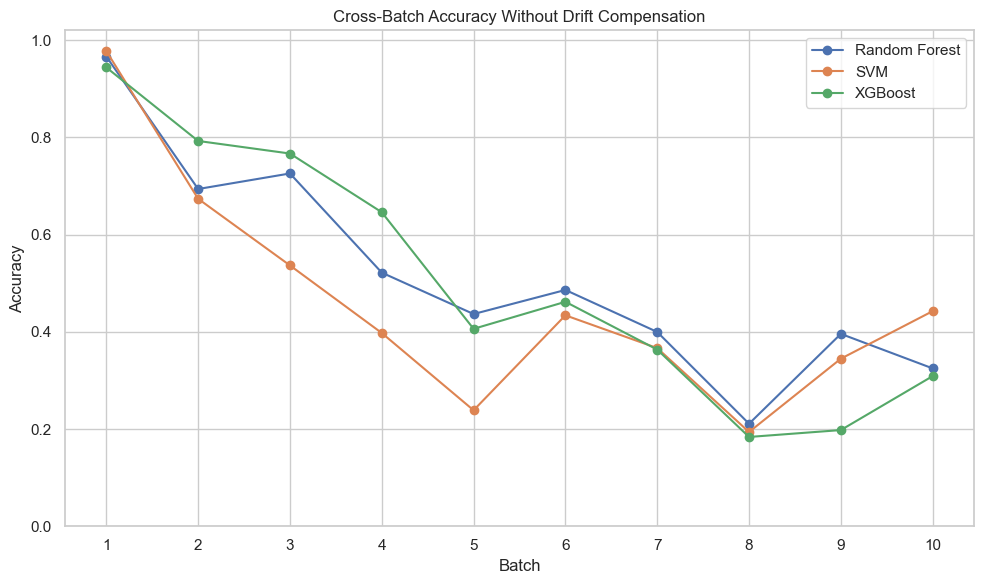

In [61]:
base_tables = {m: metrics_table(runs["none"]["preds"][m]) for m in MODEL_NAMES}

baseline_acc = pd.DataFrame({"Batch": BATCHES})
for m in MODEL_NAMES:
    baseline_acc[m] = base_tables[m]["accuracy"].values

print("Baseline accuracy (Batch 1 hold-out):")
display(baseline_acc.iloc[[0]].round(4))
print("\nCross-batch accuracy (Batches 2-10), no compensation:")
display(baseline_acc.iloc[1:].round(4))
save_table(baseline_acc, "baseline_cross_batch_accuracy")

plt.figure(figsize=(10, 6))
for m in MODEL_NAMES:
    plt.plot(baseline_acc["Batch"], baseline_acc[m], marker="o", label=m)
plt.xticks(BATCHES)
plt.ylim(0, 1.02)
plt.xlabel("Batch"); plt.ylabel("Accuracy")
plt.title("Cross-Batch Accuracy Without Drift Compensation")
plt.legend()
save_fig("01_baseline_cross_batch_accuracy")

## 10. Batch-wise Performance Degradation

Degradation of batch *k* = accuracy(batch *k*) − accuracy(Batch 1 hold-out). Negative values show how much accuracy is lost to drift.

,Batch,Random Forest change,Random Forest relative drop %,SVM change,SVM relative drop %,XGBoost change,XGBoost relative drop %
0,2,-0.2726,28.2070,-0.3039,31.0881,-0.1512,16.0217
1,3,-0.2406,24.8959,-0.4410,45.1095,-0.1771,18.7654
2,4,-0.4446,46.0061,-0.5800,59.3346,-0.2979,31.5587
3,5,-0.5297,54.8223,-0.7389,75.5937,-0.5377,56.9737
4,6,-0.4802,49.6957,-0.5436,55.6112,-0.4821,51.0776
5,7,-0.5666,58.6390,-0.6111,62.5121,-0.5804,61.4959
6,8,-0.7554,78.1759,-0.7837,80.1665,-0.7601,80.5394
7,9,-0.5705,59.0450,-0.6328,64.7395,-0.7459,79.0350
8,10,-0.6416,66.3950,-0.5350,54.7328,-0.6349,67.2725


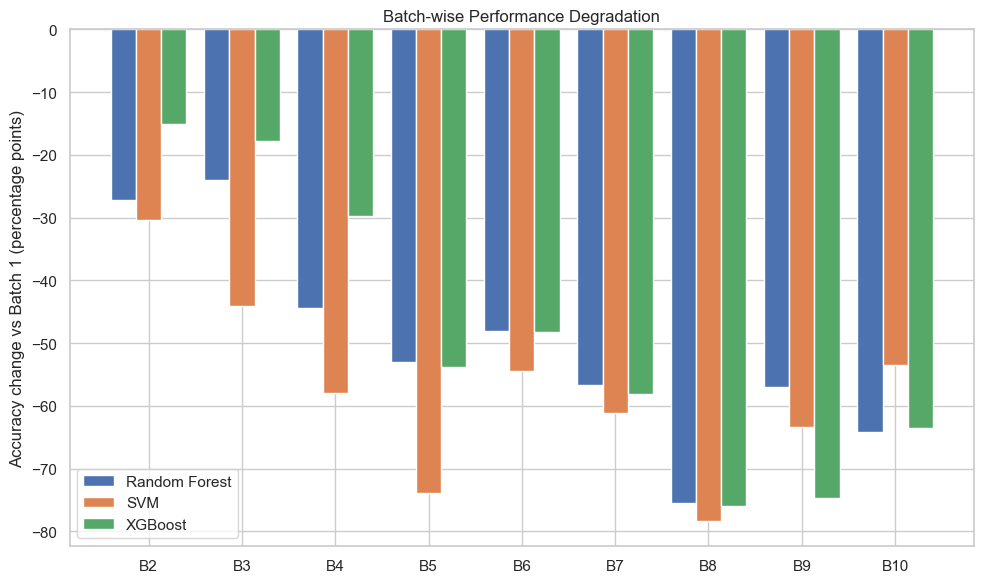

In [62]:
degradation = pd.DataFrame({"Batch": BATCHES[1:]})
for m in MODEL_NAMES:
    degradation[m + " change"] = baseline_acc[m].values[1:] - baseline_acc[m].values[0]
    degradation[m + " relative drop %"] = 100 * (baseline_acc[m].values[0] - baseline_acc[m].values[1:]) / baseline_acc[m].values[0]

display(degradation.round(4))
save_table(degradation, "performance_degradation")

fig, ax = plt.subplots(figsize=(10, 6))
width = 0.27
for i, m in enumerate(MODEL_NAMES):
    ax.bar(np.arange(9) + (i - 1) * width, degradation[m + " change"] * 100, width, label=m)
ax.set_xticks(range(9)); ax.set_xticklabels([f"B{b_no}" for b_no in BATCHES[1:]])
ax.set_ylabel("Accuracy change vs Batch 1 (percentage points)")
ax.set_title("Batch-wise Performance Degradation")
ax.legend()
save_fig("02_performance_degradation")

## 11. Selected Model (Finalised)

The model that **keeps the highest average accuracy on the later batches** is selected, because Batch 1 accuracy alone does not predict robustness to drift.

In [63]:
selection_df = pd.DataFrame({
    "Model": MODEL_NAMES,
    "Baseline accuracy (Batch 1)": [baseline_acc[m].values[0] for m in MODEL_NAMES],
    "Avg cross-batch accuracy": [baseline_acc[m].values[1:].mean() for m in MODEL_NAMES],
    "Std cross-batch accuracy": [baseline_acc[m].values[1:].std(ddof=1) for m in MODEL_NAMES],
    "Worst batch": [baseline_acc[m].values[1:].min() for m in MODEL_NAMES],
    "Avg change vs baseline": [(baseline_acc[m].values[1:] - baseline_acc[m].values[0]).mean() for m in MODEL_NAMES],
})
display(selection_df.round(4))
save_table(selection_df, "model_selection")

SELECTED_MODEL = selection_df.loc[selection_df["Avg cross-batch accuracy"].idxmax(), "Model"]
print("FINAL SELECTED MODEL:", SELECTED_MODEL)
if "selected_model" in globals():
    print("Same as the choice made in Part 1:", selected_model == SELECTED_MODEL)

,Model,Baseline accuracy (Batch 1),Avg cross-batch accuracy,Std cross-batch accuracy,Worst batch,Avg change vs baseline
0,Random Forest,0.9663,0.4661,0.1651,0.2109,-0.5002
1,SVM,0.9775,0.4031,0.1454,0.1939,-0.5744
2,XGBoost,0.9438,0.4586,0.2290,0.1837,-0.4853


FINAL SELECTED MODEL: Random Forest
Same as the choice made in Part 1: True


## 12. Sensor Drift Detection

Drift is quantified by comparing every batch with the reference Batch 1.

| Measure | Meaning |
|---|---|
| Mean shift | average over sensors of \|mean(batch) − mean(Batch 1)\| / std(Batch 1) |
| Variance shift | average over sensors of \|log(var(batch) / var(Batch 1))\| |
| KS (distribution shift) | Kolmogorov-Smirnov statistic per sensor, averaged (0 = identical, 1 = disjoint) |
| **Drift score** | KS computed **separately for every gas** and averaged, so a change in the gas mixture between batches is not mistaken for sensor drift |

### 12.1 Batch-wise sensor mean and variance

,Batch,Mean of sensor means,Mean of sensor variances,Mean shift (sigma),Variance shift
0,1,4576.1921,5.149622e+08,0.0000,0.0000
1,2,4711.8299,2.259212e+08,0.6624,1.2834
2,3,3633.9173,1.133888e+08,0.9360,0.9453
3,4,3044.7392,9.175951e+07,1.6711,1.2549
4,5,4472.7123,9.397511e+07,1.2158,0.8975
5,6,2486.4039,3.921222e+07,0.6395,1.1975
6,7,2262.9910,3.676779e+07,0.6663,1.2002
7,8,1449.0491,1.373544e+07,0.5485,2.2258
8,9,1233.6865,1.052477e+07,0.5963,2.7393
9,10,2471.0679,1.257035e+08,0.4495,0.8132


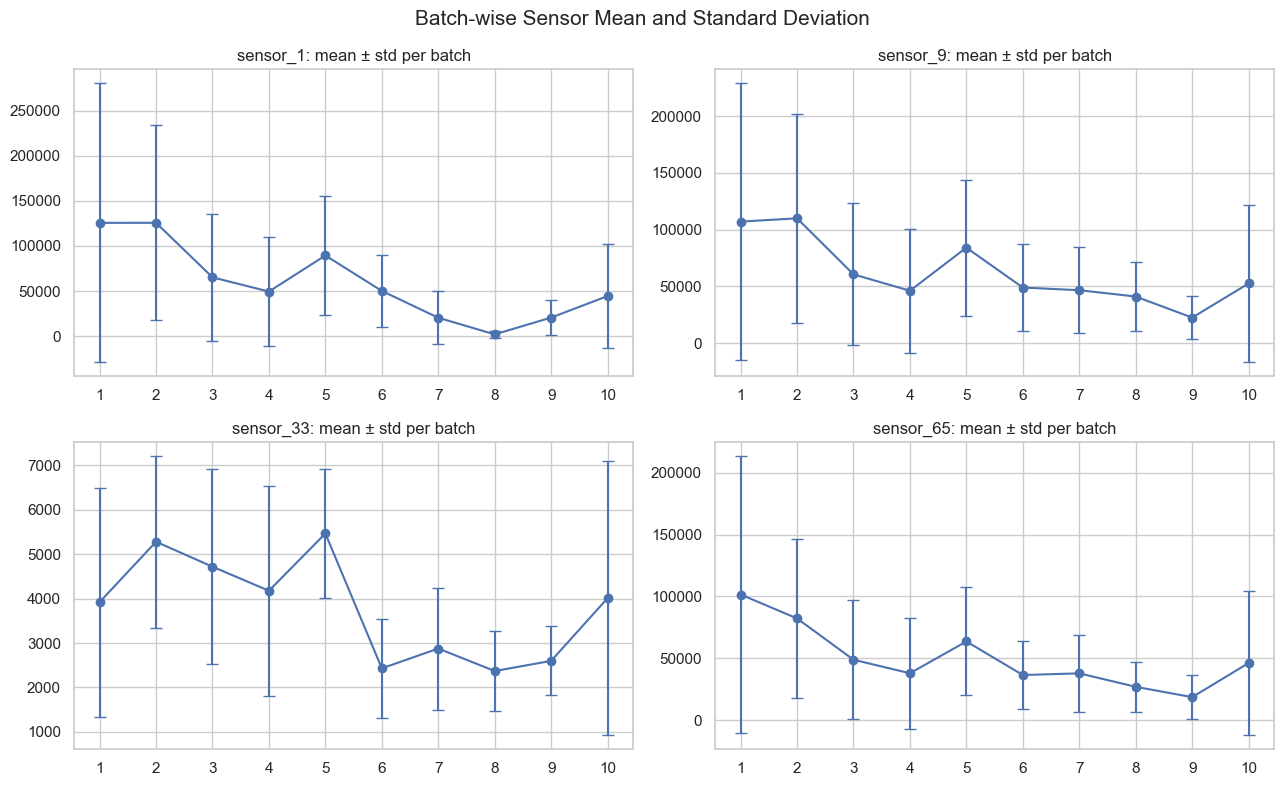

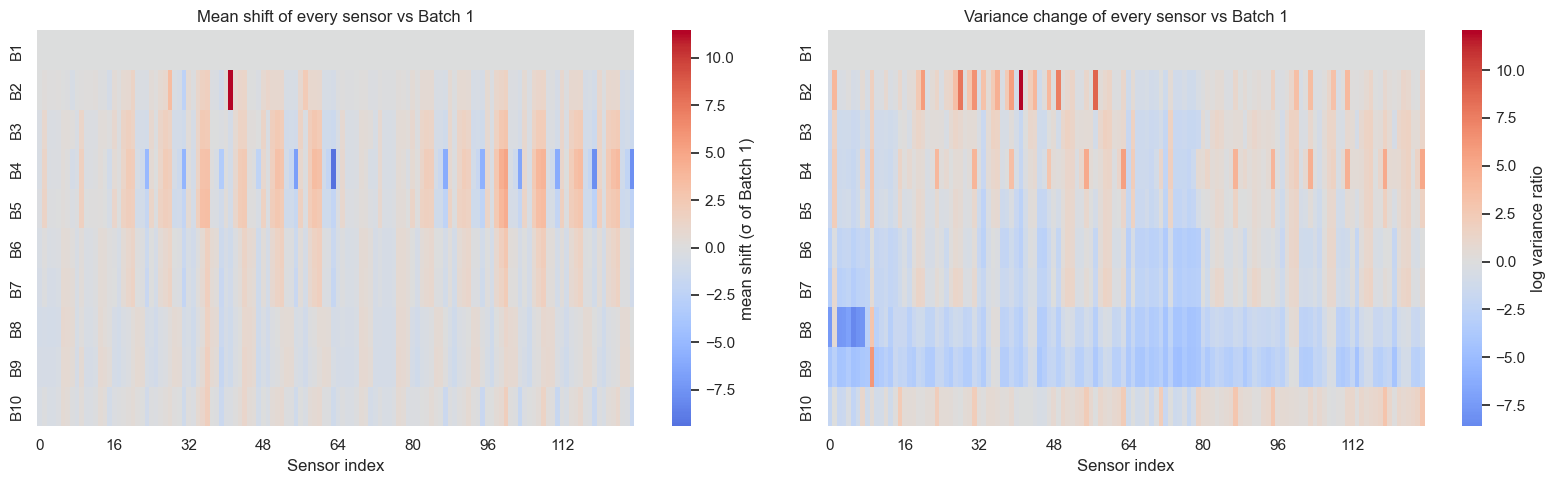

In [64]:
mean_b = np.array([X[batch == b_no].mean(axis=0) for b_no in BATCHES])      # 10 x 128
var_b = np.array([X[batch == b_no].var(axis=0, ddof=1) for b_no in BATCHES])
std_b = np.sqrt(var_b)

batch_stats = pd.DataFrame({
    "Batch": BATCHES,
    "Mean of sensor means": mean_b.mean(axis=1),
    "Mean of sensor variances": var_b.mean(axis=1),
    "Mean shift (sigma)": np.mean(np.abs(mean_b - mean_b[0]) / std_b[0], axis=1),
    "Variance shift": np.mean(np.abs(np.log(var_b / var_b[0])), axis=1),
})
display(batch_stats.round(4))
save_table(batch_stats, "batch_wise_mean_variance")

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, s in zip(axes.ravel(), [0, 8, 32, 64]):
    ax.errorbar(BATCHES, mean_b[:, s], yerr=std_b[:, s], marker="o", capsize=4)
    ax.set_title(f"sensor_{s + 1}: mean ± std per batch")
    ax.set_xticks(BATCHES)
fig.suptitle("Batch-wise Sensor Mean and Standard Deviation", fontsize=15)
save_fig("03_batchwise_mean_std_examples")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap((mean_b - mean_b[0]) / std_b[0], cmap="coolwarm", center=0, ax=axes[0],
            yticklabels=[f"B{b_no}" for b_no in BATCHES], xticklabels=16, cbar_kws={"label": "mean shift (σ of Batch 1)"})
axes[0].set_title("Mean shift of every sensor vs Batch 1"); axes[0].set_xlabel("Sensor index")
sns.heatmap(np.log(var_b / var_b[0]), cmap="coolwarm", center=0, ax=axes[1],
            yticklabels=[f"B{b_no}" for b_no in BATCHES], xticklabels=16, cbar_kws={"label": "log variance ratio"})
axes[1].set_title("Variance change of every sensor vs Batch 1"); axes[1].set_xlabel("Sensor index")
save_fig("04_mean_variance_shift_heatmaps")

### 12.2 Distribution shift

The distribution of a sensor in Batch 1 is compared with later batches. The KS statistic gives one number per sensor and batch.

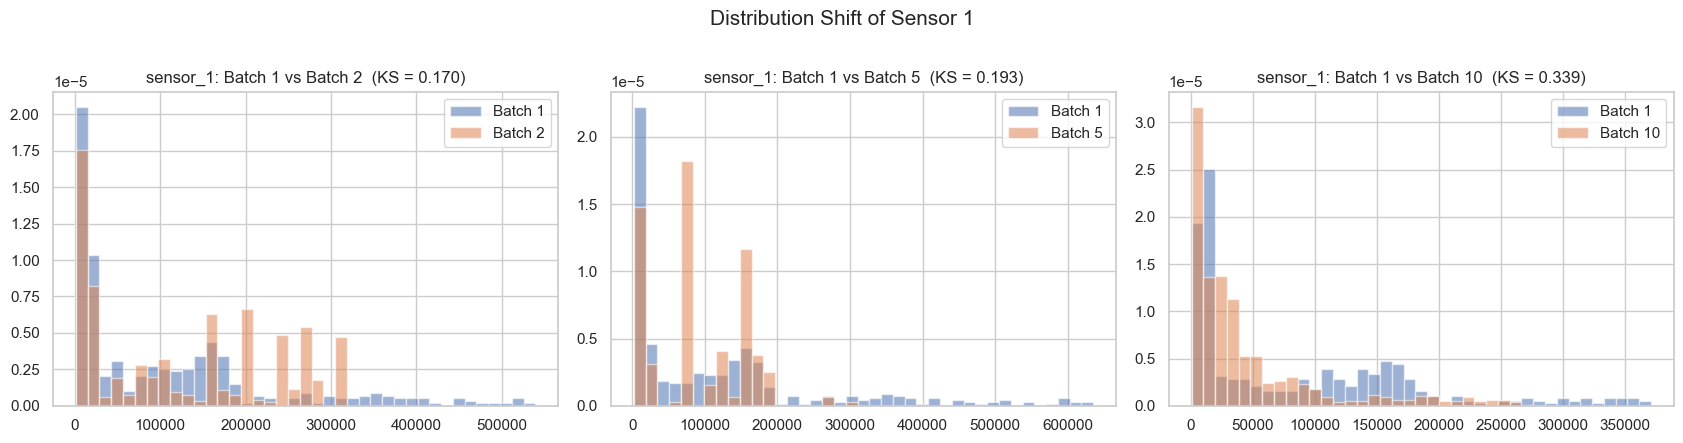

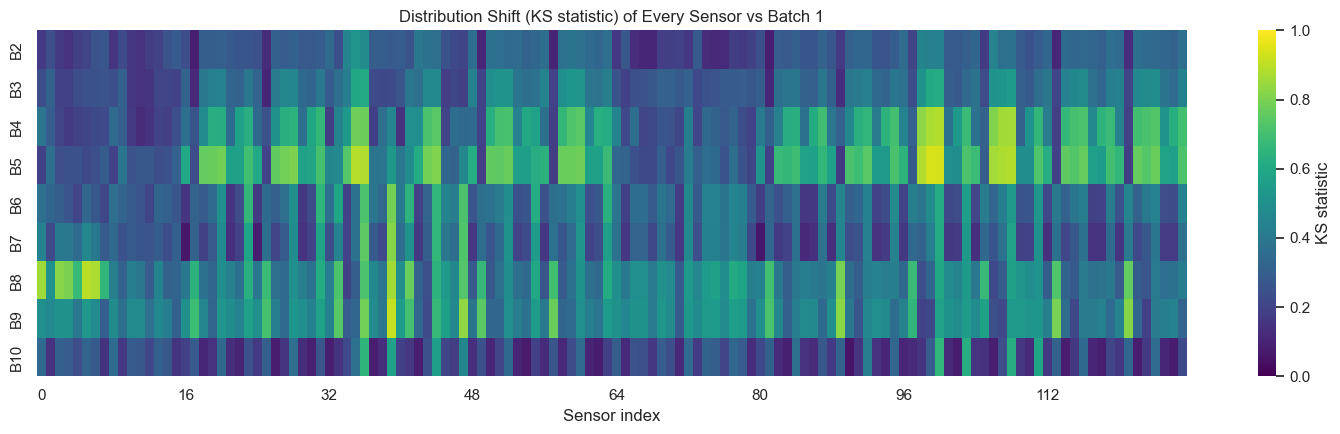

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, b_no in zip(axes, [2, 5, 10]):
    ref_vals, cur_vals = X[batch == REF_BATCH, 0], X[batch == b_no, 0]
    lo, hi = np.percentile(np.concatenate([ref_vals, cur_vals]), [1, 99])
    bins = np.linspace(lo, hi, 40)
    ax.hist(ref_vals, bins=bins, alpha=0.55, density=True, label="Batch 1")
    ax.hist(cur_vals, bins=bins, alpha=0.55, density=True, label=f"Batch {b_no}")
    ax.set_title(f"sensor_1: Batch 1 vs Batch {b_no}  (KS = {ks_stat(ref_vals, cur_vals):.3f})")
    ax.legend()
fig.suptitle("Distribution Shift of Sensor 1", fontsize=15)
save_fig("05_distribution_shift_sensor1")

ks_matrix = np.array([[ks_stat(X[batch == REF_BATCH, j], X[batch == b_no, j]) for j in range(128)] for b_no in BATCHES[1:]])
plt.figure(figsize=(15, 4.5))
sns.heatmap(ks_matrix, cmap="viridis", vmin=0, vmax=1, yticklabels=[f"B{b_no}" for b_no in BATCHES[1:]],
            xticklabels=16, cbar_kws={"label": "KS statistic"})
plt.title("Distribution Shift (KS statistic) of Every Sensor vs Batch 1"); plt.xlabel("Sensor index")
save_fig("06_ks_heatmap_all_sensors")

### 12.3 Drift score and Drift score vs Batch

,Batch,mean_shift,var_shift,ks_pooled,drift_score
0,1,0.0000,0.0000,0.0000,0.0000
1,2,0.6624,1.2834,0.2720,0.4472
2,3,0.9360,0.9453,0.3399,0.5055
3,4,1.6711,1.2549,0.4586,0.6647
4,5,1.2158,0.8975,0.5250,0.7014
5,6,0.6395,1.1975,0.3544,0.6264
6,7,0.6663,1.2002,0.3164,0.5301
7,8,0.5485,2.2258,0.4680,0.6998
8,9,0.5963,2.7393,0.4704,0.7422
9,10,0.4495,0.8132,0.2232,0.4254


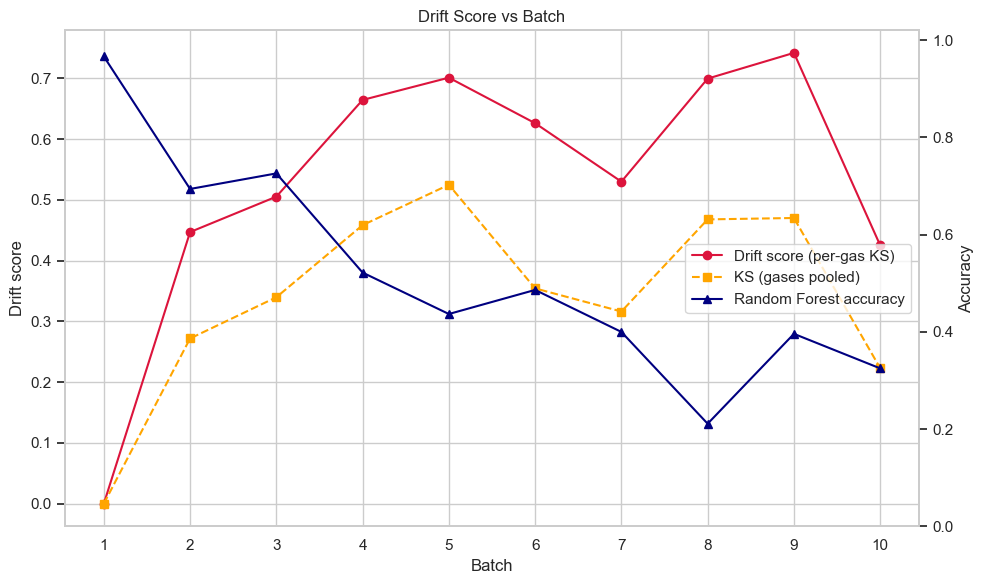

Drift score vs accuracy: Pearson r = -0.411 (p = 0.2724), Spearman rho = -0.300 (p = 0.4328)


In [66]:
drift_raw = drift_table(X, y, batch)
display(drift_raw.round(4))
save_table(drift_raw, "drift_score_raw")

acc_sel_raw = baseline_acc[SELECTED_MODEL].values
fig, ax1 = plt.subplots(figsize=(10, 6))
ax1.plot(drift_raw["Batch"], drift_raw["drift_score"], "o-", color="crimson", label="Drift score (per-gas KS)")
ax1.plot(drift_raw["Batch"], drift_raw["ks_pooled"], "s--", color="orange", label="KS (gases pooled)")
ax1.set_xlabel("Batch"); ax1.set_ylabel("Drift score"); ax1.set_xticks(BATCHES)
ax2 = ax1.twinx()
ax2.plot(BATCHES, acc_sel_raw, "^-", color="navy", label=f"{SELECTED_MODEL} accuracy")
ax2.set_ylabel("Accuracy"); ax2.set_ylim(0, 1.02); ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="center right")
plt.title("Drift Score vs Batch")
save_fig("07_drift_score_vs_batch")

r_p, p_p = stats.pearsonr(drift_raw["drift_score"].values[1:], acc_sel_raw[1:])
r_s, p_s = stats.spearmanr(drift_raw["drift_score"].values[1:], acc_sel_raw[1:])
print(f"Drift score vs accuracy: Pearson r = {r_p:.3f} (p = {p_p:.4f}), Spearman rho = {r_s:.3f} (p = {p_s:.4f})")

### 12.4 PCA before drift compensation

PCA is fitted on Batch 1 only and later batches are projected onto the same axes, so any movement of a batch away from the Batch 1 cloud is drift.

Explained variance (PC1, PC2): [0.578 0.237]


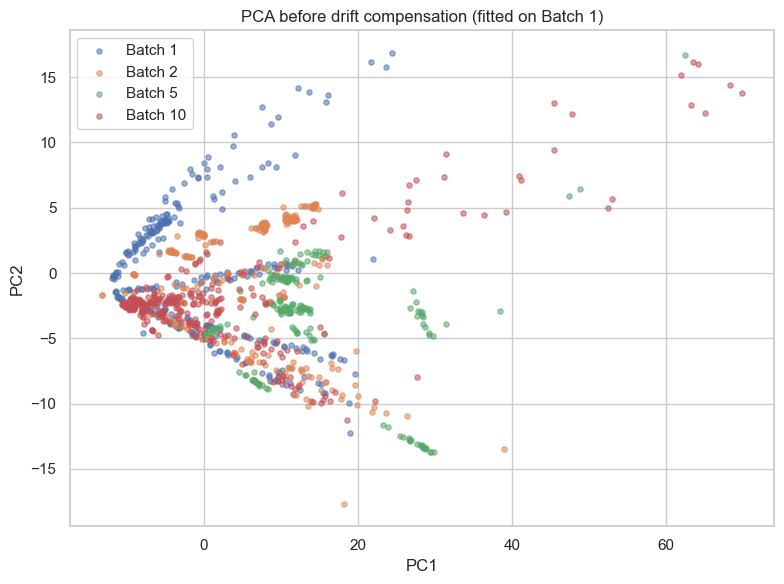

In [67]:
from sklearn.decomposition import PCA


def pca_projection(Xmat, shown=(1, 2, 5, 10), per_batch=300, seed=RANDOM_STATE):
    ref_mask = batch == REF_BATCH
    sc = StandardScaler().fit(Xmat[ref_mask])
    pca = PCA(n_components=2, random_state=seed).fit(sc.transform(Xmat[ref_mask]))
    rng = np.random.default_rng(seed)
    out = {}
    for b_no in shown:
        idx = np.where(batch == b_no)[0]
        idx = rng.choice(idx, size=min(per_batch, len(idx)), replace=False)
        out[b_no] = (pca.transform(sc.transform(Xmat[idx])), y[idx])
    return out, pca


def plot_pca(ax, projection, title):
    for b_no, (P, _) in projection.items():
        ax.scatter(P[:, 0], P[:, 1], s=14, alpha=0.55, label=f"Batch {b_no}")
    ax.set_title(title); ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()


proj_before, pca_before = pca_projection(X)
print("Explained variance (PC1, PC2):", pca_before.explained_variance_ratio_.round(3))
fig, ax = plt.subplots(figsize=(8, 6))
plot_pca(ax, proj_before, "PCA before drift compensation (fitted on Batch 1)")
save_fig("08_pca_before_compensation")

## 13. Drift Compensation

Three label-free techniques are implemented in `BatchCompensator`. Every batch (including Batch 1 itself) is transformed with statistics computed from that batch's own unlabelled samples, **relative to the reference Batch 1**:

1. **Batch-wise Standardization:** `x' = (x − mean_batch) / std_batch`
2. **Reference Mean Alignment:** `x' = x − mean_batch + mean_ref`
3. **Reference CORAL Alignment:** matches mean **and covariance** to Batch 1: `x' = ((x − mean_batch)/σ_ref · C_batch^(-1/2) · C_ref^(1/2)) · σ_ref + mean_ref`, with a ridge term for stability.

The classifier is then trained on the compensated Batch 1 training split and tested on compensated Batches 1-10.

done: Batch-wise Standardization
done: Reference Mean Alignment
done: Reference CORAL Alignment

Selected model: Random Forest


,Batch,No compensation,Batch-wise Standardization,Reference Mean Alignment,Reference CORAL Alignment
0,1,0.9663,0.9663,0.9663,0.9663
1,2,0.6937,0.7339,0.8055,0.6865
2,3,0.7257,0.6135,0.3550,0.4596
3,4,0.5217,0.6025,0.3540,0.4845
4,5,0.4365,0.6853,0.6497,0.6751
5,6,0.4861,0.8161,0.5357,0.7300
6,7,0.3997,0.4273,0.2740,0.5298
7,8,0.2109,0.4184,0.1020,0.3878
8,9,0.3957,0.4043,0.1298,0.3021
9,10,0.3247,0.3878,0.3192,0.4131


,No compensation,Batch-wise Standardization,Reference Mean Alignment,Reference CORAL Alignment
Average (batches 2-10),0.4661,0.5654,0.3917,0.5187


BEST COMPENSATION METHOD: Batch-wise Standardization
Note: the technique is chosen on the same batches it is reported on, so validate on new batches before claiming the exact gain.


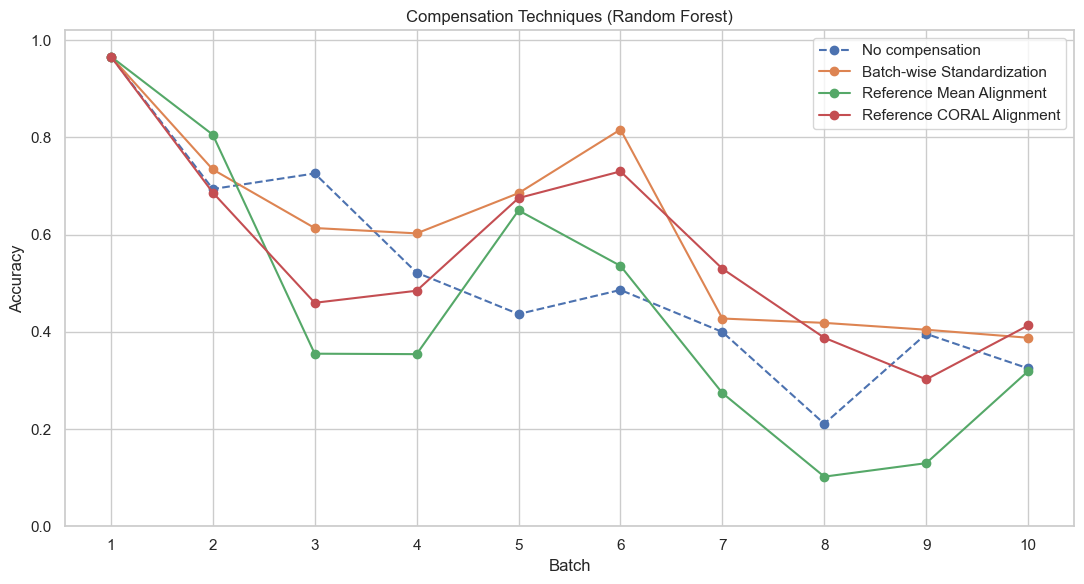

In [68]:
METHODS = [m for m in COMPENSATION_METHODS if m != "none"]

for method in METHODS:
    runs[method] = run_setup_a(X, y, batch, method=method)
    print("done:", COMPENSATION_METHODS[method])

method_acc = pd.DataFrame({"Batch": BATCHES})
method_acc["No compensation"] = base_tables[SELECTED_MODEL]["accuracy"].values
for method in METHODS:
    method_acc[COMPENSATION_METHODS[method]] = metrics_table(runs[method]["preds"][SELECTED_MODEL])["accuracy"].values

print(f"\nSelected model: {SELECTED_MODEL}")
display(method_acc.round(4))

avg_row = method_acc.iloc[1:, 1:].mean().rename("Average (batches 2-10)")
display(avg_row.to_frame().T.round(4))
save_table(method_acc, "compensation_methods_accuracy")

BEST_METHOD = max(METHODS, key=lambda m: metrics_table(runs[m]["preds"][SELECTED_MODEL])["accuracy"].values[1:].mean())
print("BEST COMPENSATION METHOD:", COMPENSATION_METHODS[BEST_METHOD])
print("Note: the technique is chosen on the same batches it is reported on, so validate on new batches before claiming the exact gain.")

plt.figure(figsize=(11, 6))
for col in method_acc.columns[1:]:
    plt.plot(method_acc["Batch"], method_acc[col], marker="o", linestyle="--" if col == "No compensation" else "-", label=col)
plt.xticks(BATCHES); plt.ylim(0, 1.02)
plt.xlabel("Batch"); plt.ylabel("Accuracy"); plt.title(f"Compensation Techniques ({SELECTED_MODEL})")
plt.legend()
save_fig("09_compensation_methods_comparison")

### 13.1 Effect of the correction on the raw sensor values

Batch 10 (the most drifted batch) is moved back onto the Batch 1 reference.

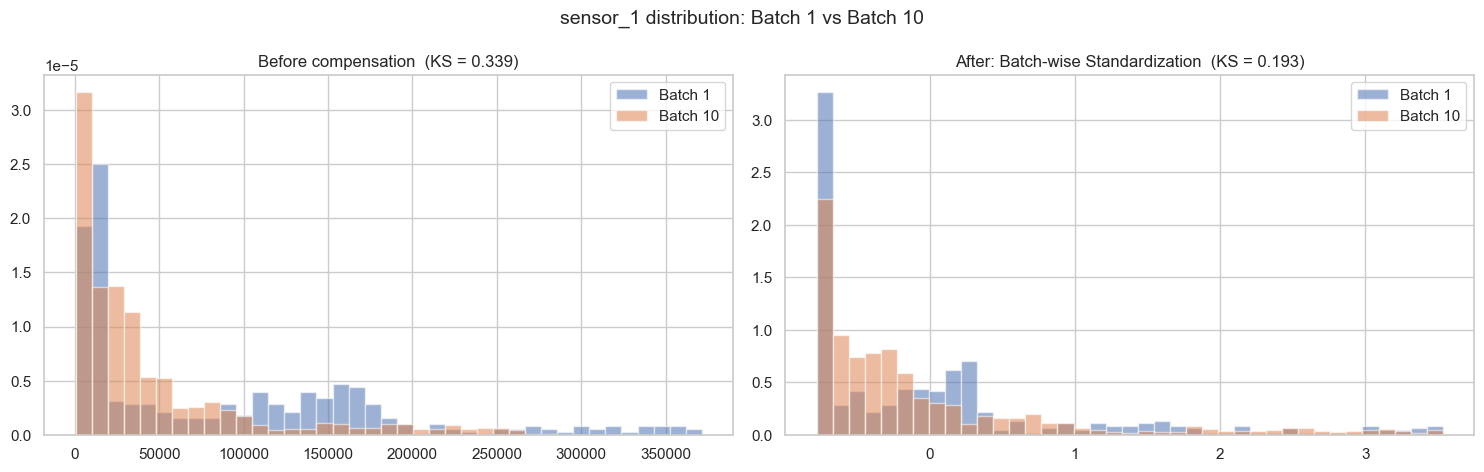

,Batch,Drift score before,Drift score after
0,1,0.0000,0.0000
1,2,0.4472,0.5039
2,3,0.5055,0.4596
3,4,0.6647,0.5863
4,5,0.7014,0.5648
5,6,0.6264,0.5091
6,7,0.5301,0.3895
7,8,0.6998,0.5987
8,9,0.7422,0.6483
9,10,0.4254,0.4083


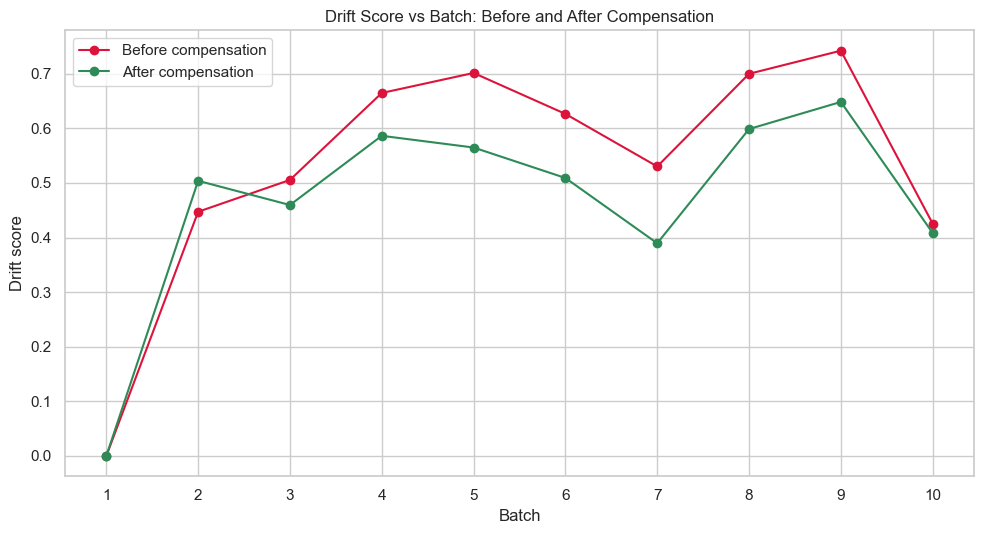

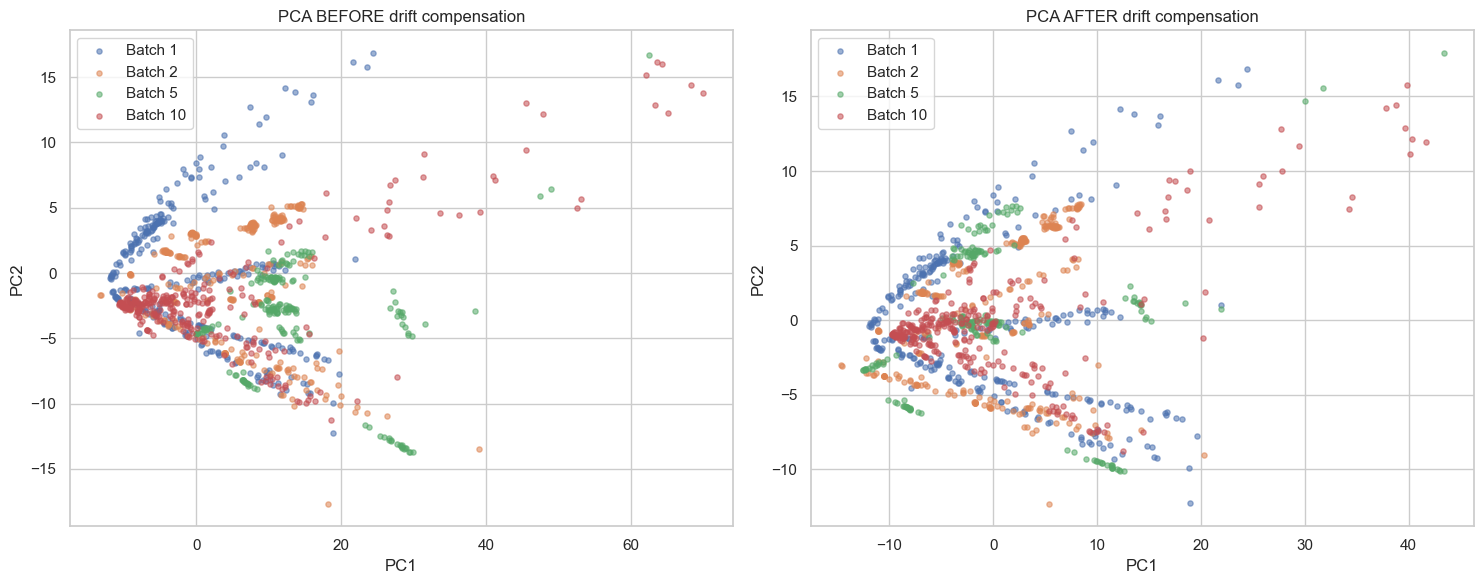

In [69]:
best = runs[BEST_METHOD]
X_comp = best["Xt"]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
for ax, Xmat, title in [(axes[0], X, "Before compensation"), (axes[1], X_comp, f"After: {COMPENSATION_METHODS[BEST_METHOD]}")]:
    ref_vals, cur_vals = Xmat[batch == REF_BATCH, 0], Xmat[batch == 10, 0]
    lo, hi = np.percentile(np.concatenate([ref_vals, cur_vals]), [1, 99])
    bins = np.linspace(lo, hi, 40)
    ax.hist(ref_vals, bins=bins, alpha=0.55, density=True, label="Batch 1")
    ax.hist(cur_vals, bins=bins, alpha=0.55, density=True, label="Batch 10")
    ax.set_title(f"{title}  (KS = {ks_stat(ref_vals, cur_vals):.3f})"); ax.legend()
fig.suptitle("sensor_1 distribution: Batch 1 vs Batch 10", fontsize=14)
save_fig("10_distribution_before_after_compensation")

drift_comp = drift_table(X_comp, y, batch)
drift_cmp_df = pd.DataFrame({"Batch": BATCHES, "Drift score before": drift_raw["drift_score"], "Drift score after": drift_comp["drift_score"]})
display(drift_cmp_df.round(4))
save_table(drift_cmp_df, "drift_score_before_after")

plt.figure(figsize=(10, 5.5))
plt.plot(BATCHES, drift_cmp_df["Drift score before"], "o-", color="crimson", label="Before compensation")
plt.plot(BATCHES, drift_cmp_df["Drift score after"], "o-", color="seagreen", label="After compensation")
plt.xticks(BATCHES); plt.xlabel("Batch"); plt.ylabel("Drift score"); plt.title("Drift Score vs Batch: Before and After Compensation")
plt.legend()
save_fig("11_drift_score_before_after")

proj_after, pca_after = pca_projection(X_comp)
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=False)
plot_pca(axes[0], proj_before, "PCA BEFORE drift compensation")
plot_pca(axes[1], proj_after, "PCA AFTER drift compensation")
save_fig("12_pca_before_after_compensation")

## 14. Test the Selected Model on Compensated Data

The same model type (`SELECTED_MODEL`) is evaluated on compensated Batches 1-10. Accuracy, precision, recall and F1 (macro-averaged over the six gases) are compared with the uncompensated results.

,Batch,Accuracy before,Accuracy after,Accuracy gain (pp),Precision before,Precision after,Recall before,Recall after,F1 before,F1 after
0,1,0.9663,0.9663,0.0000,0.9725,0.9725,0.9340,0.9340,0.9468,0.9468
1,2,0.6937,0.7339,4.0193,0.6394,0.5553,0.7217,0.6833,0.6444,0.5405
2,3,0.7257,0.6135,-11.2232,0.5618,0.5421,0.5474,0.4561,0.5189,0.4797
3,4,0.5217,0.6025,8.0745,0.5335,0.5889,0.4710,0.4991,0.3833,0.5239
4,5,0.4365,0.6853,24.8731,0.4412,0.5390,0.5800,0.5676,0.4578,0.5418
5,6,0.4861,0.8161,33.0000,0.3556,0.7541,0.4645,0.6911,0.3784,0.7182
6,7,0.3997,0.4273,2.7678,0.2701,0.6442,0.4310,0.4503,0.3084,0.4650
7,8,0.2109,0.4184,20.7483,0.2482,0.2837,0.3000,0.4068,0.1330,0.2784
8,9,0.3957,0.4043,0.8511,0.3122,0.3577,0.4091,0.4807,0.2946,0.3333
9,10,0.3247,0.3878,6.3056,0.3725,0.5482,0.3247,0.3878,0.2403,0.3359


All cross-batch samples pooled (Batches 2-10):


,Metric,Before,After,Gain (pp)
0,Accuracy,0.4577,0.5383,8.0579
1,Precision (macro),0.5300,0.6116,8.1609
2,Recall (macro),0.4331,0.4958,6.2719
3,F1 (macro),0.3595,0.5162,15.6699


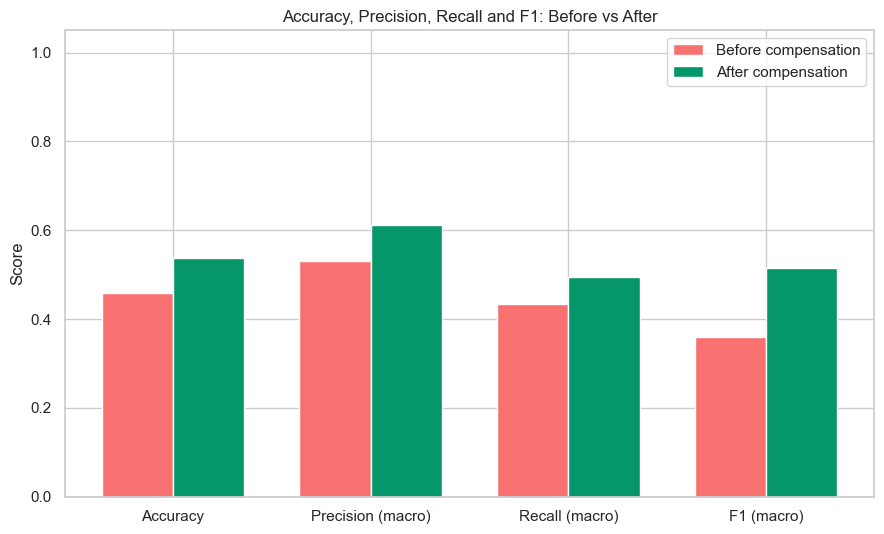

In [70]:
tb = base_tables[SELECTED_MODEL]
ta = metrics_table(best["preds"][SELECTED_MODEL])

before_after = pd.DataFrame({
    "Batch": BATCHES,
    "Accuracy before": tb["accuracy"], "Accuracy after": ta["accuracy"],
    "Accuracy gain (pp)": 100 * (ta["accuracy"] - tb["accuracy"]),
    "Precision before": tb["precision"], "Precision after": ta["precision"],
    "Recall before": tb["recall"], "Recall after": ta["recall"],
    "F1 before": tb["f1"], "F1 after": ta["f1"],
})
display(before_after.round(4))
save_table(before_after, "before_after_per_batch")

yb, pb = pooled(runs["none"]["preds"][SELECTED_MODEL])
ya, pa = pooled(best["preds"][SELECTED_MODEL])
pooled_before, pooled_after = batch_metrics(yb, pb), batch_metrics(ya, pa)
pooled_df = pd.DataFrame({"Metric": ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)"],
                          "Before": list(pooled_before.values()), "After": list(pooled_after.values())})
pooled_df["Gain (pp)"] = 100 * (pooled_df["After"] - pooled_df["Before"])
print("All cross-batch samples pooled (Batches 2-10):")
display(pooled_df.round(4))
save_table(pooled_df, "precision_recall_f1_before_after")

x_pos = np.arange(len(pooled_df))
plt.figure(figsize=(9, 5.5))
plt.bar(x_pos - 0.18, pooled_df["Before"], 0.36, label="Before compensation", color="#f87171")
plt.bar(x_pos + 0.18, pooled_df["After"], 0.36, label="After compensation", color="#059669")
plt.xticks(x_pos, pooled_df["Metric"]); plt.ylim(0, 1.05); plt.ylabel("Score")
plt.title("Accuracy, Precision, Recall and F1: Before vs After"); plt.legend()
save_fig("13_metrics_before_after")

### 14.1 Confusion matrix before vs after

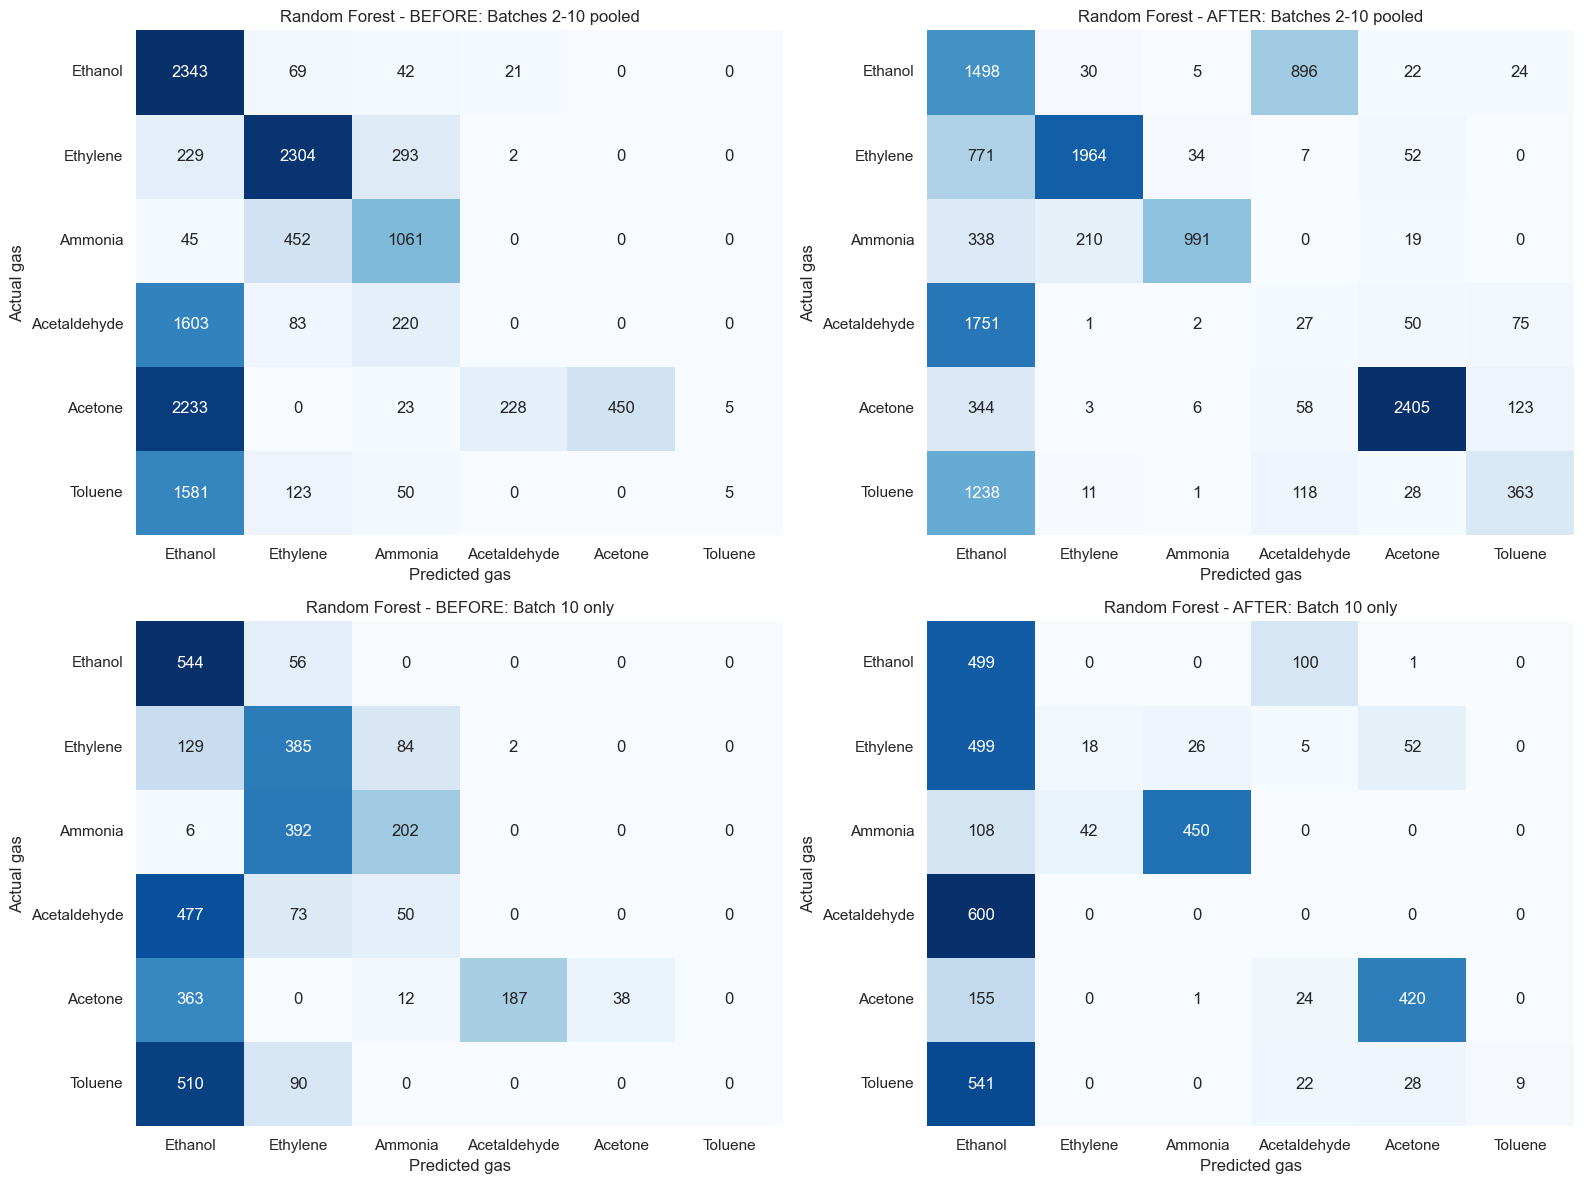

,Gas,Recall before,F1 before,Recall after,F1 after
0,Ethanol,0.9467,0.4459,0.6053,0.3560
1,Ethylene,0.8147,0.7865,0.6945,0.7783
2,Ammonia,0.6810,0.6535,0.6361,0.7632
3,Acetaldehyde,0.0000,0.0000,0.0142,0.0179
4,Acetone,0.1531,0.2656,0.8183,0.8722
5,Toluene,0.0028,0.0057,0.2064,0.3097


In [71]:
labels_txt = [GAS_NAMES[g] for g in GAS_LABELS]
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
panels = [
    (axes[0, 0], confusion_matrix(yb, pb, labels=GAS_LABELS), "BEFORE: Batches 2-10 pooled"),
    (axes[0, 1], confusion_matrix(ya, pa, labels=GAS_LABELS), "AFTER: Batches 2-10 pooled"),
    (axes[1, 0], confusion_matrix(*runs["none"]["preds"][SELECTED_MODEL][10], labels=GAS_LABELS), "BEFORE: Batch 10 only"),
    (axes[1, 1], confusion_matrix(*best["preds"][SELECTED_MODEL][10], labels=GAS_LABELS), "AFTER: Batch 10 only"),
]
for ax, cm, title in panels:
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_txt, yticklabels=labels_txt, ax=ax, cbar=False)
    ax.set_title(f"{SELECTED_MODEL} - {title}"); ax.set_xlabel("Predicted gas"); ax.set_ylabel("Actual gas")
save_fig("14_confusion_matrix_before_after")

per_gas = pd.DataFrame({"Gas": labels_txt})
for tag, (yt_, yp_) in {"before": (yb, pb), "after": (ya, pa)}.items():
    _, rec, f1_, _ = precision_recall_fscore_support(yt_, yp_, labels=GAS_LABELS, zero_division=0)
    per_gas[f"Recall {tag}"], per_gas[f"F1 {tag}"] = rec, f1_
display(per_gas.round(4))
save_table(per_gas, "per_gas_recall_f1_before_after")

### 14.2 Cross-batch accuracy before vs after (all three models) and accuracy improvement

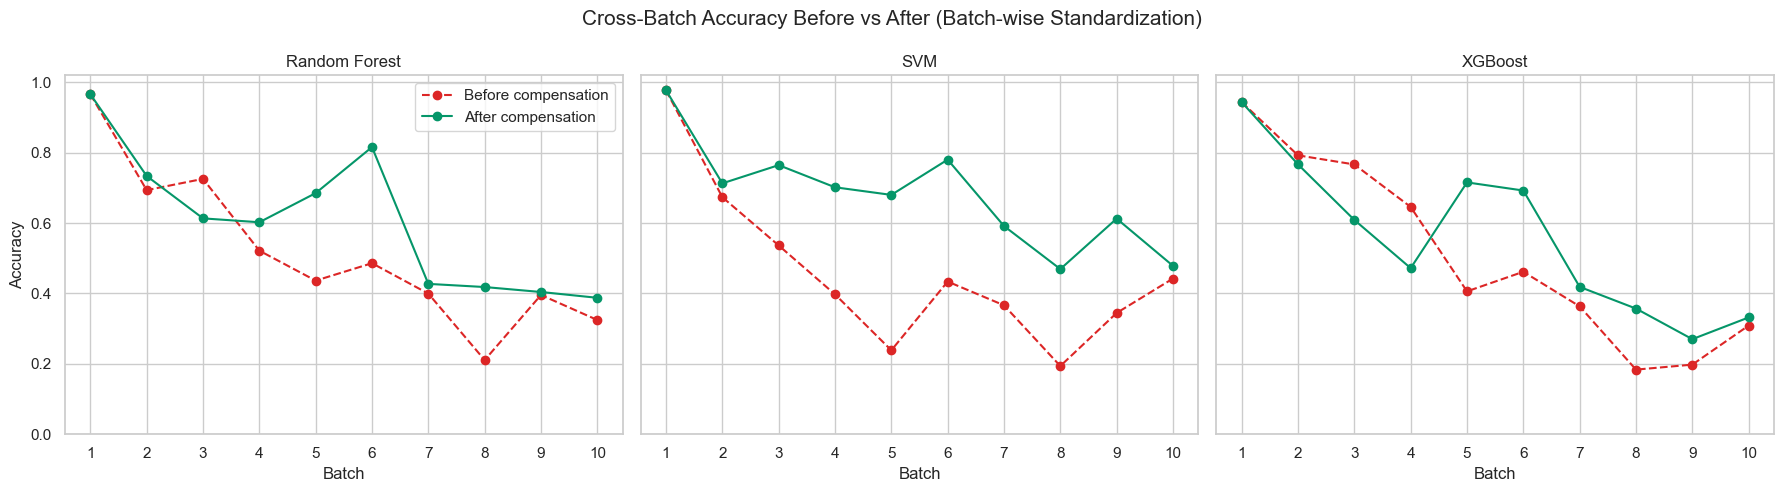

,Model,Avg accuracy before,Avg accuracy after,Improvement (pp),Error reduction %
0,Random Forest,0.4661,0.5654,9.9352,18.6084
1,SVM,0.4031,0.6437,24.0570,40.3020
2,XGBoost,0.4586,0.5149,5.6385,10.4138


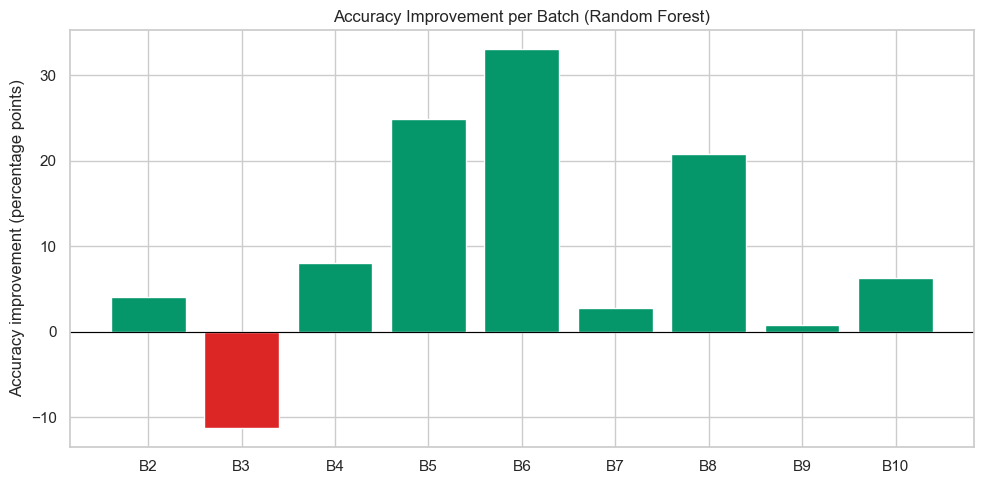

Average accuracy gain on Batches 2-10: +9.94 percentage points


In [72]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
improvement_rows = []
for ax, m in zip(axes, MODEL_NAMES):
    before_m = base_tables[m]["accuracy"].values
    after_m = metrics_table(best["preds"][m])["accuracy"].values
    ax.plot(BATCHES, before_m, "o--", color="#dc2626", label="Before compensation")
    ax.plot(BATCHES, after_m, "o-", color="#059669", label="After compensation")
    ax.set_title(m); ax.set_xticks(BATCHES); ax.set_xlabel("Batch"); ax.set_ylim(0, 1.02)
    improvement_rows.append(dict(
        Model=m,
        **{"Avg accuracy before": before_m[1:].mean(), "Avg accuracy after": after_m[1:].mean(),
           "Improvement (pp)": 100 * (after_m[1:].mean() - before_m[1:].mean()),
           "Error reduction %": 100 * (1 - (1 - after_m[1:].mean()) / (1 - before_m[1:].mean()))}))
axes[0].set_ylabel("Accuracy"); axes[0].legend()
fig.suptitle(f"Cross-Batch Accuracy Before vs After ({COMPENSATION_METHODS[BEST_METHOD]})", fontsize=15)
save_fig("15_cross_batch_accuracy_before_after")

improvement_df = pd.DataFrame(improvement_rows)
display(improvement_df.round(4))
save_table(improvement_df, "accuracy_improvement_all_models")

gain_pp = 100 * (ta["accuracy"].values[1:] - tb["accuracy"].values[1:])
plt.figure(figsize=(10, 5))
plt.bar([f"B{b_no}" for b_no in BATCHES[1:]], gain_pp, color=["#059669" if g >= 0 else "#dc2626" for g in gain_pp])
plt.axhline(0, color="black", lw=0.8)
plt.ylabel("Accuracy improvement (percentage points)")
plt.title(f"Accuracy Improvement per Batch ({SELECTED_MODEL})")
save_fig("16_accuracy_improvement_per_batch")

print(f"Average accuracy gain on Batches 2-10: {gain_pp.mean():+.2f} percentage points")

## 15. Statistical Validation

Evidence is collected at three levels:

1. **Batch level (n = 9 batches):** mean ± standard deviation, paired t-test, Wilcoxon signed-rank test, Cohen's d_z and a 95% confidence interval for the improvement.
2. **Seed level:** the whole experiment (stratified split + model seed) is repeated for 5 random seeds, reported as mean ± std.
3. **Sample level:** McNemar's exact test on every cross-batch sample and a bootstrap confidence interval for the accuracy gain.

In [73]:
acc_before_b = tb["accuracy"].values[1:]
acc_after_b = ta["accuracy"].values[1:]

batch_stats_test = paired_stats(acc_before_b, acc_after_b)
summary_rows = [
    ("Accuracy before (mean ± std, n=9 batches)", f"{100*batch_stats_test['mean_before']:.2f} ± {100*batch_stats_test['std_before']:.2f} %"),
    ("Accuracy after (mean ± std, n=9 batches)", f"{100*batch_stats_test['mean_after']:.2f} ± {100*batch_stats_test['std_after']:.2f} %"),
    ("Mean improvement ± std", f"{100*batch_stats_test['mean_improvement']:+.2f} ± {100*batch_stats_test['std_improvement']:.2f} pp"),
    ("95% CI of improvement", f"[{100*batch_stats_test['ci_low']:.2f}, {100*batch_stats_test['ci_high']:.2f}] pp"),
    ("Paired t-test", f"t = {batch_stats_test['t_stat']:.3f}, p = {batch_stats_test['p_ttest']:.4f}"),
    ("Wilcoxon signed-rank", f"W = {batch_stats_test['w_stat']:.1f}, p = {batch_stats_test['p_wilcoxon']:.4f}"),
    ("Cohen's d_z", f"{batch_stats_test['cohen_dz']:.3f}"),
    ("Batches improved", f"{batch_stats_test['batches_improved']} / {batch_stats_test['n']}"),
]

mcn = mcnemar_exact(yb, pb, pa)
boot = bootstrap_improvement(yb, pb, pa)
summary_rows += [
    (f"McNemar exact test ({len(yb)} samples)", f"fixed {mcn['fixed_by_compensation']}, broken {mcn['broken_by_compensation']}, p = {mcn['p_value']:.2e}"),
    ("Bootstrap 95% CI of accuracy gain", f"{100*boot['mean']:+.2f} pp [{100*boot['ci_low']:.2f}, {100*boot['ci_high']:.2f}]"),
]
print("Compensation:", COMPENSATION_METHODS[BEST_METHOD], "| Model:", SELECTED_MODEL)
validation_df = pd.DataFrame(summary_rows, columns=["Measure", "Result"])
display(validation_df)
save_table(validation_df, "statistical_validation_summary")

method_stats = []
for method in METHODS:
    acc_m = metrics_table(runs[method]["preds"][SELECTED_MODEL])["accuracy"].values[1:]
    st = paired_stats(acc_before_b, acc_m)
    method_stats.append([COMPENSATION_METHODS[method], 100 * st["mean_improvement"], 100 * st["ci_low"], 100 * st["ci_high"],
                         st["p_ttest"], st["p_wilcoxon"], st["cohen_dz"], st["batches_improved"]])
method_stats_df = pd.DataFrame(method_stats, columns=["Technique", "Mean gain (pp)", "CI low", "CI high", "t-test p", "Wilcoxon p", "Cohen d_z", "Batches improved"])
display(method_stats_df.round(4))
save_table(method_stats_df, "statistical_tests_all_methods")

Compensation: Batch-wise Standardization | Model: Random Forest


,Measure,Result
0,"Accuracy before (mean ± std, n=9 batches)",46.61 ± 16.51 %
1,"Accuracy after (mean ± std, n=9 batches)",56.54 ± 16.11 %
2,Mean improvement ± std,+9.94 ± 13.72 pp
3,95% CI of improvement,"[-0.61, 20.48] pp"
4,Paired t-test,"t = 2.173, p = 0.0615"
5,Wilcoxon signed-rank,"W = 6.0, p = 0.0547"
6,Cohen's d_z,0.724
7,Batches improved,8 / 9
8,McNemar exact test (13465 samples),"fixed 2931, broken 1846, p = 6.64e-56"
9,Bootstrap 95% CI of accuracy gain,"+8.04 pp [7.13, 9.01]"


,Technique,Mean gain (pp),CI low,CI high,t-test p,Wilcoxon p,Cohen d_z,Batches improved
0,Batch-wise Standardization,9.9352,-0.6087,20.4790,0.0615,0.0547,0.7243,8
1,Reference Mean Alignment,-7.4440,-21.6825,6.7945,0.2624,0.3008,-0.4019,3
2,Reference CORAL Alignment,5.2621,-7.7289,18.2530,0.3776,0.4961,0.3114,5


,Batch,Before mean,Before std,After mean,After std
0,2,0.7124,0.0307,0.7436,0.0216
1,3,0.7414,0.0105,0.6521,0.0235
2,4,0.5627,0.0309,0.6137,0.0447
3,5,0.4406,0.0136,0.6863,0.0116
4,6,0.4883,0.0033,0.7787,0.0255
5,7,0.3934,0.0117,0.4382,0.0161
6,8,0.2170,0.0305,0.4034,0.0313
7,9,0.3838,0.0533,0.3302,0.0257
8,10,0.3392,0.0134,0.3637,0.0255


Average cross-batch accuracy over 5 seeds:
  before: 47.54 ± 1.74 %
  after : 55.66 ± 0.99 %
  paired t-test over seeds: p = 0.0002647


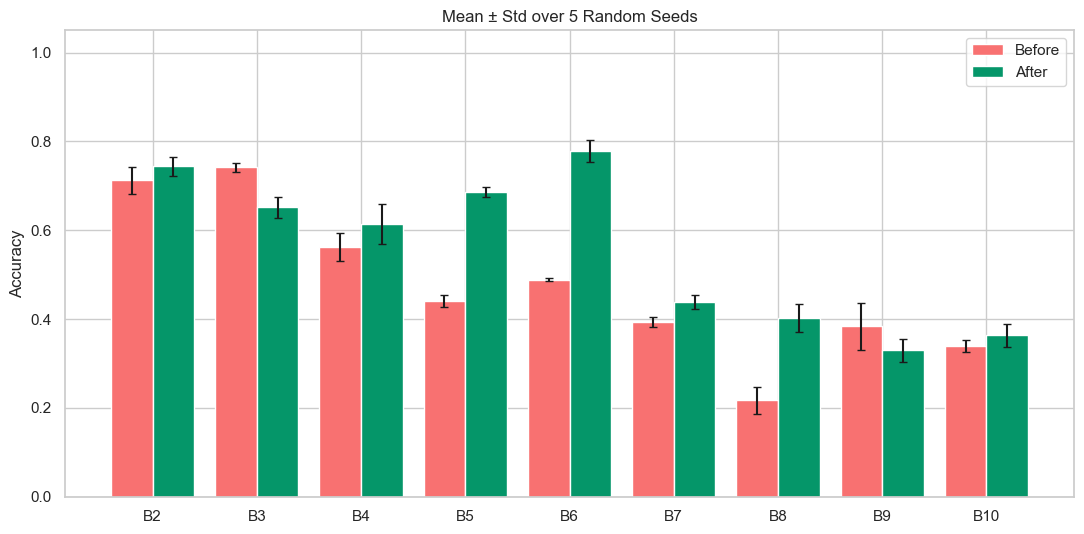

In [74]:
SEEDS = (0, 1, 2, 3, 4)
seeds_before = multi_seed_accuracy(X, y, batch, "none", SELECTED_MODEL, SEEDS)            # seeds x 9 batches
seeds_after = multi_seed_accuracy(X, y, batch, BEST_METHOD, SELECTED_MODEL, SEEDS)

seed_table = pd.DataFrame({
    "Batch": BATCHES[1:],
    "Before mean": seeds_before.mean(axis=0), "Before std": seeds_before.std(axis=0, ddof=1),
    "After mean": seeds_after.mean(axis=0), "After std": seeds_after.std(axis=0, ddof=1),
})
display(seed_table.round(4))
save_table(seed_table, "multi_seed_mean_std")

avg_b, avg_a = seeds_before.mean(axis=1), seeds_after.mean(axis=1)
seed_test = paired_stats(avg_b, avg_a)
print(f"Average cross-batch accuracy over {len(SEEDS)} seeds:")
print(f"  before: {100*avg_b.mean():.2f} ± {100*avg_b.std(ddof=1):.2f} %")
print(f"  after : {100*avg_a.mean():.2f} ± {100*avg_a.std(ddof=1):.2f} %")
print(f"  paired t-test over seeds: p = {seed_test['p_ttest']:.4g}")

fig, ax = plt.subplots(figsize=(11, 5.5))
xs = np.arange(9)
ax.bar(xs - 0.2, seed_table["Before mean"], 0.4, yerr=seed_table["Before std"], capsize=3, label="Before", color="#f87171")
ax.bar(xs + 0.2, seed_table["After mean"], 0.4, yerr=seed_table["After std"], capsize=3, label="After", color="#059669")
ax.set_xticks(xs); ax.set_xticklabels([f"B{b_no}" for b_no in BATCHES[1:]]); ax.set_ylim(0, 1.05)
ax.set_ylabel("Accuracy"); ax.set_title(f"Mean ± Std over {len(SEEDS)} Random Seeds"); ax.legend()
save_fig("17_multi_seed_mean_std")

### 15.1 Interpretation

* With only nine batches the t-test has low power and is sensitive to the very uneven size of the gains, so the **Wilcoxon test, McNemar test and bootstrap interval** (which use every test sample) are the stronger evidence.
* A negative correlation between drift score and accuracy confirms that the drift measure explains the lost accuracy.
* The compensation technique was chosen on the same batches that are reported, so the exact gain is slightly optimistic; confirm on newly collected batches before relying on it.

## 16. Optional: Protocol B, Sequential Batch-wise Training

For batch *k* the model is trained on **all earlier batches** (1..k-1) and tested on batch *k*. Every batch is compensated towards Batch 1 individually before training and testing. Set `RUN_SEQUENTIAL = False` to skip this slower experiment.

,Test batch,Train batches,Train samples,Test samples,Accuracy before,Accuracy after,Gain (pp)
0,2,1-1,445,1244,0.7540,0.7452,-0.8842
1,3,1-2,1689,1586,0.9306,0.7831,-14.7541
2,4,1-3,3275,161,0.8447,0.7826,-6.2112
3,5,1-4,3436,197,0.9391,0.9848,4.5685
4,6,1-5,3633,2300,0.7130,0.7178,0.4783
5,7,1-6,5933,3613,0.7542,0.7077,-4.6499
6,8,1-7,9546,294,0.8707,0.4660,-40.4762
7,9,1-8,9840,470,0.8426,0.6787,-16.3830
8,10,1-9,10310,3600,0.6100,0.5569,-5.3056


Mean accuracy before: 0.8066 ± 0.1077
Mean accuracy after : 0.7137 ± 0.1463


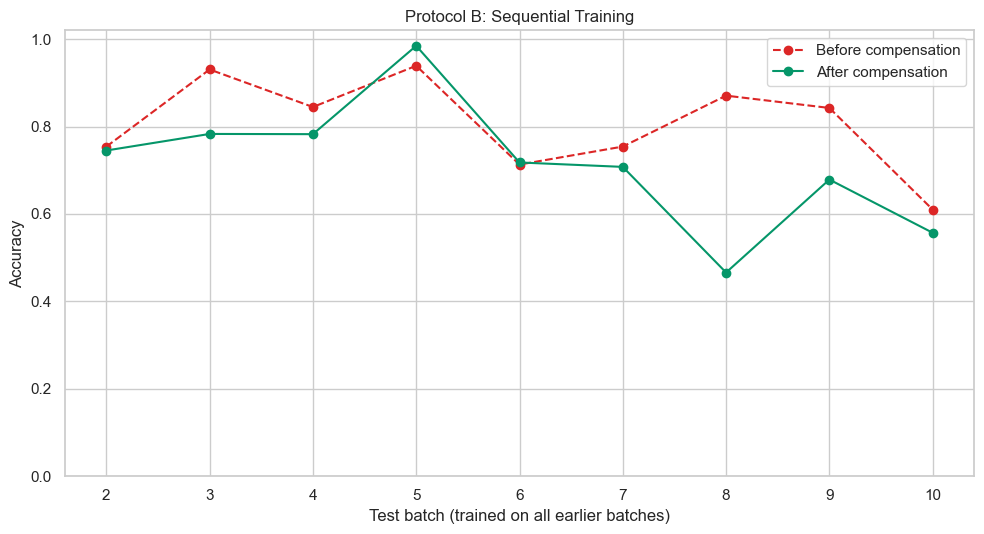

In [75]:
RUN_SEQUENTIAL = True

if RUN_SEQUENTIAL:
    comp_seq = BatchCompensator(BEST_METHOD).fit(X, batch)
    X_seq = compensate_all(X, batch, comp_seq)
    seq_rows = []
    for k in BATCHES[1:]:
        tr, te = batch < k, batch == k
        row = {"Test batch": k, "Train batches": f"1-{k-1}", "Train samples": int(tr.sum()), "Test samples": int(te.sum())}
        for tag, Xmat in [("before", X), ("after", X_seq)]:
            sc = StandardScaler().fit(Xmat[tr])
            clf = GasClassifier(SELECTED_MODEL, RANDOM_STATE).fit(sc.transform(Xmat[tr]), y[tr])
            row[f"Accuracy {tag}"] = accuracy_score(y[te], clf.predict(sc.transform(Xmat[te])))
        seq_rows.append(row)
    seq_df = pd.DataFrame(seq_rows)
    seq_df["Gain (pp)"] = 100 * (seq_df["Accuracy after"] - seq_df["Accuracy before"])
    display(seq_df.round(4))
    print(f"Mean accuracy before: {seq_df['Accuracy before'].mean():.4f} ± {seq_df['Accuracy before'].std(ddof=1):.4f}")
    print(f"Mean accuracy after : {seq_df['Accuracy after'].mean():.4f} ± {seq_df['Accuracy after'].std(ddof=1):.4f}")
    save_table(seq_df, "protocol_b_sequential")

    plt.figure(figsize=(10, 5.5))
    plt.plot(seq_df["Test batch"], seq_df["Accuracy before"], "o--", color="#dc2626", label="Before compensation")
    plt.plot(seq_df["Test batch"], seq_df["Accuracy after"], "o-", color="#059669", label="After compensation")
    plt.xticks(BATCHES[1:]); plt.ylim(0, 1.02); plt.xlabel("Test batch (trained on all earlier batches)")
    plt.ylabel("Accuracy"); plt.title("Protocol B: Sequential Training"); plt.legend()
    save_fig("18_protocol_b_sequential")

## 17. Final Model Pipeline

```
Input (128 sensor values + batch id)
   -> Preprocessing   (type / shape / finite check)
   -> Drift Compensation (BatchCompensator, reference = Batch 1)
   -> Selected Model  (StandardScaler + SELECTED_MODEL)
   -> Gas Class
```
The pipeline is trained once on the compensated Batch 1 training split, exactly as evaluated above.

In [76]:
final_run = run_setup_a(X, y, batch, BEST_METHOD, [SELECTED_MODEL], probability=True)
raw_run = run_setup_a(X, y, batch, "none", [SELECTED_MODEL], probability=True)

final_pipeline = GasDriftPipeline(final_run["comp"], final_run["scaler"], final_run["models"][SELECTED_MODEL], BEST_METHOD, SELECTED_MODEL)
baseline_pipeline = GasDriftPipeline(raw_run["comp"], raw_run["scaler"], raw_run["models"][SELECTED_MODEL], "none", SELECTED_MODEL)

# end-to-end check on every cross-batch sample, one batch at a time
rows = []
for k in BATCHES[1:]:
    idx = np.where(batch == k)[0]
    lab_c, _ = final_pipeline.predict(X[idx], batch=k)
    lab_r, _ = baseline_pipeline.predict(X[idx])
    rows.append([k, accuracy_score(y[idx], lab_r), accuracy_score(y[idx], lab_c)])
check = pd.DataFrame(rows, columns=["Batch", "Baseline pipeline", "Compensated pipeline"])
display(check.round(4))
print("Mean accuracy: baseline pipeline %.4f | compensated pipeline %.4f" % (check.iloc[:, 1].mean(), check.iloc[:, 2].mean()))

# single-sample demonstration
sample_idx = np.random.default_rng(1).choice(np.where(batch == 9)[0])
label, proba = final_pipeline.predict(X[sample_idx], batch=9)
print("\nDemo sample from Batch 9")
print("  True gas     :", GAS_NAMES[y[sample_idx]])
print("  Predicted gas:", GAS_NAMES[int(label[0])], f"({100 * proba[0].max():.1f}% confidence)")

,Batch,Baseline pipeline,Compensated pipeline
0,2,0.6937,0.7339
1,3,0.7257,0.6135
2,4,0.5217,0.6025
3,5,0.4365,0.6853
4,6,0.4861,0.8161
5,7,0.3997,0.4273
6,8,0.2109,0.4184
7,9,0.3957,0.4043
8,10,0.3247,0.3878


Mean accuracy: baseline pipeline 0.4661 | compensated pipeline 0.5654

Demo sample from Batch 9
  True gas     : Ammonia
  Predicted gas: Ammonia (35.0% confidence)


## 18. Final Results Table

In [77]:
final_results = pd.DataFrame({
    "Batch": BATCHES,
    "Drift score before": drift_raw["drift_score"].values,
    "Drift score after": drift_comp["drift_score"].values,
    "Accuracy before": tb["accuracy"].values,
    "Accuracy after": ta["accuracy"].values,
    "Improvement (pp)": 100 * (ta["accuracy"].values - tb["accuracy"].values),
    "F1 before": tb["f1"].values,
    "F1 after": ta["f1"].values,
})
display(final_results.round(4))

headline = {
    "selected_model": SELECTED_MODEL,
    "compensation_method": COMPENSATION_METHODS[BEST_METHOD],
    "reference_batch": REF_BATCH,
    "baseline_batch1_accuracy": float(tb["accuracy"].values[0]),
    "avg_cross_batch_accuracy_before": float(acc_before_b.mean()),
    "avg_cross_batch_accuracy_after": float(acc_after_b.mean()),
    "improvement_pp": float(100 * (acc_after_b.mean() - acc_before_b.mean())),
    "std_before": float(acc_before_b.std(ddof=1)),
    "std_after": float(acc_after_b.std(ddof=1)),
    "p_ttest": float(batch_stats_test["p_ttest"]),
    "p_wilcoxon": float(batch_stats_test["p_wilcoxon"]),
    "p_mcnemar": float(mcn["p_value"]),
}
print(json.dumps(headline, indent=2))

,Batch,Drift score before,Drift score after,Accuracy before,Accuracy after,Improvement (pp),F1 before,F1 after
0,1,0.0000,0.0000,0.9663,0.9663,0.0000,0.9468,0.9468
1,2,0.4472,0.5039,0.6937,0.7339,4.0193,0.6444,0.5405
2,3,0.5055,0.4596,0.7257,0.6135,-11.2232,0.5189,0.4797
3,4,0.6647,0.5863,0.5217,0.6025,8.0745,0.3833,0.5239
4,5,0.7014,0.5648,0.4365,0.6853,24.8731,0.4578,0.5418
5,6,0.6264,0.5091,0.4861,0.8161,33.0000,0.3784,0.7182
6,7,0.5301,0.3895,0.3997,0.4273,2.7678,0.3084,0.4650
7,8,0.6998,0.5987,0.2109,0.4184,20.7483,0.1330,0.2784
8,9,0.7422,0.6483,0.3957,0.4043,0.8511,0.2946,0.3333
9,10,0.4254,0.4083,0.3247,0.3878,6.3056,0.2403,0.3359


{
  "selected_model": "Random Forest",
  "compensation_method": "Batch-wise Standardization",
  "reference_batch": 1,
  "baseline_batch1_accuracy": 0.9662921348314607,
  "avg_cross_batch_accuracy_before": 0.4660942701417102,
  "avg_cross_batch_accuracy_after": 0.5654458500273702,
  "improvement_pp": 9.935157988566006,
  "std_before": 0.16510408182890346,
  "std_after": 0.16105043845032918,
  "p_ttest": 0.06154152586250823,
  "p_wilcoxon": 0.0546875,
  "p_mcnemar": 6.642478477386531e-56
}


## 19. Save Final Graphs, Tables, Model and Results

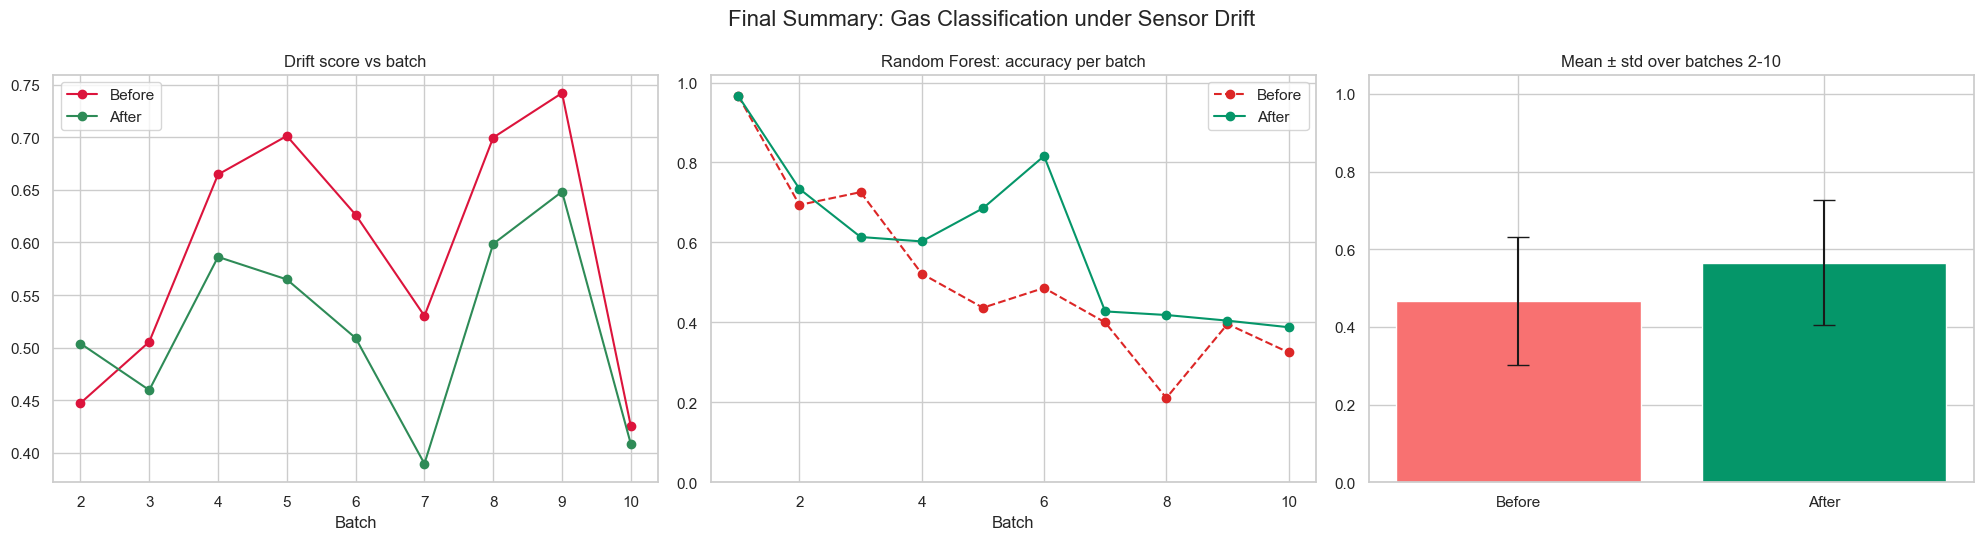

Saved files:
   baseline_pipeline_no_compensation.joblib
   figures\01_baseline_cross_batch_accuracy.png
   figures\02_performance_degradation.png
   figures\03_batchwise_mean_std_examples.png
   figures\04_mean_variance_shift_heatmaps.png
   figures\05_distribution_shift_sensor1.png
   figures\06_ks_heatmap_all_sensors.png
   figures\07_drift_score_vs_batch.png
   figures\08_pca_before_compensation.png
   figures\09_compensation_methods_comparison.png
   figures\10_distribution_before_after_compensation.png
   figures\11_drift_score_before_after.png
   figures\12_pca_before_after_compensation.png
   figures\13_metrics_before_after.png
   figures\14_confusion_matrix_before_after.png
   figures\15_cross_batch_accuracy_before_after.png
   figures\16_accuracy_improvement_per_batch.png
   figures\17_multi_seed_mean_std.png
   figures\18_protocol_b_sequential.png
   figures\19_final_summary.png
   final_gas_drift_pipeline.joblib
   final_results.json
   tables\accuracy_improvement_all_model

In [78]:
save_table(final_results, "final_results_table")

with open(OUT_DIR / "final_results.json", "w") as f:
    json.dump(headline, f, indent=2)

joblib.dump(final_pipeline, OUT_DIR / "final_gas_drift_pipeline.joblib")
joblib.dump(baseline_pipeline, OUT_DIR / "baseline_pipeline_no_compensation.joblib")

# one summary figure
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].plot(BATCHES[1:], drift_cmp_df["Drift score before"][1:], "o-", color="crimson", label="Before")
axes[0].plot(BATCHES[1:], drift_cmp_df["Drift score after"][1:], "o-", color="seagreen", label="After")
axes[0].set_title("Drift score vs batch"); axes[0].set_xlabel("Batch"); axes[0].legend()
axes[1].plot(BATCHES, tb["accuracy"], "o--", color="#dc2626", label="Before")
axes[1].plot(BATCHES, ta["accuracy"], "o-", color="#059669", label="After")
axes[1].set_title(f"{SELECTED_MODEL}: accuracy per batch"); axes[1].set_xlabel("Batch"); axes[1].set_ylim(0, 1.02); axes[1].legend()
axes[2].bar(["Before", "After"], [acc_before_b.mean(), acc_after_b.mean()], yerr=[acc_before_b.std(ddof=1), acc_after_b.std(ddof=1)],
            capsize=8, color=["#f87171", "#059669"])
axes[2].set_ylim(0, 1.05); axes[2].set_title("Mean ± std over batches 2-10")
fig.suptitle("Final Summary: Gas Classification under Sensor Drift", fontsize=16)
save_fig("19_final_summary")

print("Saved files:")
for path in sorted(OUT_DIR.rglob("*")):
    if path.is_file():
        print("  ", path.relative_to(OUT_DIR))

## 20. Flask Integration

The Flask dashboard (`app.py`) contains the **same** `BatchCompensator`, `GasClassifier`, `GasDriftPipeline`, drift and statistics functions that were used in this notebook. On first start it repeats this analysis, builds the final compensated pipeline and serves it:

```
my_project/
├── app.py
├── raw/batch1.dat ... batch10.dat
├── templates/index.html
└── static/ style.css, script.js
```

Run `python app.py` and open http://127.0.0.1:5000. The **Gas Prediction** page lets you pick the batch a reading belongs to, applies the drift compensation for that batch, and shows the compensated and uncompensated predictions side by side.

> `final_gas_drift_pipeline.joblib` saved above can be loaded in another script only if the classes `BatchCompensator`, `GasClassifier` and `GasDriftPipeline` from section 7 are defined (or imported) there first.